In [1]:
import gc
import hashlib
import itertools
import logging
import os
import warnings
from datetime import datetime
from typing import Tuple

import numpy as np
import pandas as pd
import yfinance as yf
import cvxpy as cp
import dimod
import neal
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.cluster import AgglomerativeClustering
from sklearn.covariance import LedoitWolf

warnings.filterwarnings("ignore")

MIN_ANNUALISE_DAYS = 60
MIN_OOS_DAYS_FOR_TRUST = 120

# Parameters

In [2]:
'''

MARKETS        = ["india", "usa", "europe", "japan", "crypto"]
UNIVERSE_SIZES = {"u10": 10, "u20": 20, "u30": 30, "u40": 40, "u50": 50}
CARDINALITIES  = [0.2, 0.3, 0.4]
LAMBDA_ALPHAS  = [2.0]
LOOKBACKS      = [126, 252, 504]
START_DATE     = "2022-01-01"
END_DATE       = "2026-01-01"
BACKTEST_DAYS  = 252
NUM_READS      = 1000
NUM_SWEEPS     = 3000
SA_SEEDS       = 5
PLOTS_DIR      = "plots/experiment_qubo_final/"

'''

'\n\nMARKETS        = ["india", "usa", "europe", "japan", "crypto"]\nUNIVERSE_SIZES = {"u10": 10, "u20": 20, "u30": 30, "u40": 40, "u50": 50}\nCARDINALITIES  = [0.2, 0.3, 0.4]\nLAMBDA_ALPHAS  = [2.0]\nLOOKBACKS      = [126, 252, 504]\nSTART_DATE     = "2022-01-01"\nEND_DATE       = "2026-01-01"\nBACKTEST_DAYS  = 252\nNUM_READS      = 1000\nNUM_SWEEPS     = 3000\nSA_SEEDS       = 5\nPLOTS_DIR      = "plots/experiment_qubo_final/"\n\n'

In [3]:
MARKETS        = ["india", "usa", "europe", "japan", "crypto"]
UNIVERSE_SIZES = {"u10": 10, "u20": 20, "u30": 30, "u40": 40, "u50": 50}
CARDINALITIES  = [0.2, 0.3, 0.4]   # B = max(1, int(ratio × u_size))
Q_VALUES       = [0.3, 0.5, 0.7]
LOOKBACKS      = [126, 252, 504]
BACKTEST_DAYS  = 252
START_DATE     = "2022-01-01"
END_DATE       = "2026-01-01"
NUM_READS      = 1000
NUM_SWEEPS     = 3000
SA_SEEDS       = 5
DIV_PENALTY    = 0.3

In [4]:
MARKET_TICKERS = {

    "india": [
        # STRONG
        "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "ICICIBANK.NS",
        "HINDUNILVR.NS", "ITC.NS", "SBIN.NS", "BHARTIARTL.NS", "LT.NS",
        "KOTAKBANK.NS", "AXISBANK.NS", "BAJFINANCE.NS", "ASIANPAINT.NS", "MARUTI.NS",
        "HCLTECH.NS", "SUNPHARMA.NS", "WIPRO.NS", "ULTRACEMCO.NS", "TITAN.NS",
        "TECHM.NS", "NESTLEIND.NS", "POWERGRID.NS", "NTPC.NS", "ONGC.NS",
        # WEAK / SPECULATIVE
        "YESBANK.NS", "SUZLON.NS", "RCOM.NS", "JPASSOCIAT.NS", "JPPOWER.NS",
        "IL&FSTRANS.NS", "VIDEOIND.NS", "RTNPOWER.NS", "IDEA.NS", "SAREGAMA.NS",
        "ORCHPHARMA.NS", "SOUTHBANK.NS", "DCBBANK.NS", "KARURVYSYA.NS", "KKCL.NS",
        "ABAN.NS", "PGEL.NS", "ROLEXRINGS.NS", "RELIGARE.NS", "NBCC.NS",
        "IRCON.NS", "JKTYRE.NS", "WOCKPHARMA.NS", "PNB.NS", "TATAMOTORS.NS",
    ],

    "usa": [
        # STRONG
        "AAPL", "MSFT", "GOOGL", "AMZN", "NVDA",
        "META", "BRK-B", "UNH", "JNJ", "JPM",
        "V", "PG", "XOM", "HD", "CVX",
        "MRK", "ABBV", "PEP", "KO", "LLY",
        "COST", "MCD", "TMO", "WMT", "TXN",
        # WEAK / SPECULATIVE
        "SPCE", "CLOV", "WKHS", "PTON", "LCID",
        "RIVN", "MVIS", "SNDL", "CTRM", "TLRY",
        "OPEN", "UWMC", "BBIG", "XELA", "CPSS",
        "BYND", "NWSA", "PRTY", "SABR", "WFRD",
        "CEQP", "RILY", "FTCH", "PACK",
    ],

    "europe": [
        # STRONG
        "ASML.AS", "NESN.SW", "NOVN.SW", "ROG.SW", "SAP.DE",
        "SIE.DE", "ALV.DE", "BAS.DE", "AIR.PA", "BNP.PA",
        "MC.PA", "OR.PA", "SHELL.AS", "HEIA.AS", "AZN.L",
        "HSBA.L", "ULVR.L", "GSK.L", "RIO.L", "ENI.MI",
        "ENEL.MI", "IBE.MC", "BBVA.MC", "NOVO-B.CO", "NOKIA.HE",
        # WEAK / SPECULATIVE
        "THG.L", "IAG.L", "NESTE.HE", "SAGA.L", "TUI1.DE",
        "HAB.DE", "LEG.DE", "VNA.DE", "CSGN.SW", "ARBN.SW",
        "TELE2.ST", "SSAB-A.ST", "ELISA.HE", "AMBU-B.CO", "CARL-B.CO",
        "MAERSK-B.CO", "WIZZ.L", "JD.L", "WPP.L", "ITV.L",
        "AUTO.L", "FERG.L", "SDGR.SW", "LONN.SW", "CRHCF",
    ],

    "japan": [
        # STRONG
        "7203.T", "6758.T", "9984.T", "6861.T", "8306.T",
        "7974.T", "4063.T", "6098.T", "9433.T", "8035.T",
        "6954.T", "2914.T", "4519.T", "7751.T", "6301.T",
        "5108.T", "8801.T", "9022.T", "3382.T", "4543.T",
        "7267.T", "6902.T", "4661.T", "8411.T", "8316.T",
        # WEAK / SPECULATIVE
        "9501.T", "6417.T", "3197.T", "4680.T", "2768.T",
        "6460.T", "4004.T", "5020.T", "9706.T", "2432.T",
        "3765.T", "4751.T", "3092.T", "6178.T", "8308.T",
        "8354.T", "4324.T", "6869.T", "7762.T", "3086.T",
        "8233.T", "9831.T", "4205.T", "9104.T", "8795.T",
    ],

    "crypto": [
        # STRONG
        "BTC-USD", "ETH-USD", "BNB-USD", "SOL-USD", "XRP-USD",
        "ADA-USD", "AVAX-USD", "LINK-USD", "DOT-USD", "LTC-USD",
        "BCH-USD", "ATOM-USD", "NEAR-USD", "ARB-USD", "AAVE-USD",
        "MKR-USD", "LDO-USD", "CRV-USD", "SNX-USD", "UNI-USD",
        "OP-USD", "FTM-USD", "INJ-USD", "STX-USD", "RNDR-USD",
        # WEAK / SPECULATIVE
        "DOGE-USD", "SHIB-USD", "FLOKI-USD", "PEPE-USD", "BONK-USD",
        "XEM-USD", "ZIL-USD", "WAVES-USD", "ICX-USD", "ONT-USD",
        "EOS-USD", "XTZ-USD", "DASH-USD", "ZEC-USD", "EGLD-USD",
        "SAND-USD", "MANA-USD", "ALGO-USD", "VET-USD", "QTUM-USD",
        "BAT-USD", "ZRX-USD", "CHZ-USD", "ENJ-USD", "1INCH-USD",
    ],
}

MARKET_BENCHMARKS = {
    "india":  "^NSEI",
    "usa":    "^GSPC",
    "europe": "^STOXX50E",
    "japan":  "^N225",
    "crypto": "BTC-USD",
}

print("Tickers loaded")

Tickers loaded


In [5]:
RISK_FREE_RATES = {
    "india":  0.065,
    "usa":    0.0525,
    "europe": 0.035,
    "japan":  0.001,
    "crypto": 0.000,
}

MARKET_FR_WINDOW = {
    "india":  21,
    "usa":    14,
    "europe": 14,
    "japan":  21,
    "crypto": 7,
}

MARKET_REBALANCE_DAYS = {
    "india":  63,
    "usa":    63,
    "europe": 42,
    "japan":  42,
    "crypto": 21,
}

MARKET_TRANSACTION_COST = {
    "india":  0.006,
    "usa":    0.002,
    "europe": 0.003,
    "japan":  0.002,
    "crypto": 0.004,
}

MARKET_MAX_WEIGHT = {
    "india":  0.40,
    "usa":    0.35,
    "europe": 0.35,
    "japan":  0.40,
    "crypto": 0.25,
}

MARKET_MAX_VOL = {
    "india":  0.75,
    "usa":    0.60,
    "europe": 0.60,
    "japan":  0.70,
    "crypto": 5.00,
}

MARKET_MAX_CORRELATION = {
    "india":  0.65,
    "usa":    0.80,
    "europe": 0.80,
    "japan":  0.85,
    "crypto": 0.75,
}

MIN_DIVERSIFICATION_RATIO = {
    "india":  1.05,
    "usa":    1.10,
    "europe": 1.10,
    "japan":  1.05,
    "crypto": 1.15,
}

UNIVERSE_SIZES = {
    "u10": 10, 
    "u20": 20, 
    "u30": 30, 
    "u40": 40, 
    "u50": 50
}

BENCHMARK_LABELS = {
    "india":  "NIFTY 50",
    "usa":    "S&P 500",
    "europe": "EURO STOXX 50",
    "japan":  "Nikkei 225",
    "crypto": "BTC",
}

# Logger

In [6]:
log_dir = "logs"
os.makedirs(log_dir, exist_ok=True)

logger = logging.getLogger('qubo_optimization')
logger.setLevel(logging.DEBUG)
for handler in logger.handlers[:]:
    handler.close()
    logger.removeHandler(handler)
logger.propagate = False

log_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
log_file      = os.path.join(log_dir, f"qubo_optimization_{log_timestamp}.log")

console_formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s', datefmt='%H:%M:%S')
file_formatter    = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')

console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_handler.setFormatter(console_formatter)

file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_handler.setFormatter(file_formatter)

logger.addHandler(console_handler)
logger.addHandler(file_handler)
logger.info(f"Logging initialized — Console: INFO+, File: DEBUG+ ({log_file})")


21:19:39 - INFO - Logging initialized — Console: INFO+, File: DEBUG+ (logs\qubo_optimization_20260426_211939.log)


# Core Functions

## Data Download

In [7]:
def download_data(market, start_date, end_date, cache_dir="data_cache"):
    if market not in MARKET_TICKERS:
        raise ValueError(f"Unknown market: '{market}'. Valid: {list(MARKET_TICKERS)}")

    os.makedirs(cache_dir, exist_ok=True)
    key          = hashlib.md5(f"{market}_{start_date}_{end_date}".encode()).hexdigest()
    prices_cache = os.path.join(cache_dir, f"{market}_{key}_prices.csv")
    volume_cache = os.path.join(cache_dir, f"{market}_{key}_volume.csv")

    logger.info(f"\n{'='*60}")
    logger.info(f"download_data: {market.upper()} | {start_date} to {end_date}")
    print(f"\n[{market.upper()}] Downloading data...")

    if os.path.exists(prices_cache) and os.path.exists(volume_cache):
        try:
            prices = pd.read_csv(prices_cache, index_col=0, parse_dates=True)
            volume = pd.read_csv(volume_cache, index_col=0, parse_dates=True)
            logger.info(f"[CACHE] Loaded: {prices.shape}")
            print(f"  [CACHE] Loaded: {prices.shape[0]} rows x {prices.shape[1]} tickers")
            return prices, volume
        except Exception as e:
            logger.warning(f"[CACHE] Read failed ({e}), re-downloading...")
            os.remove(prices_cache); os.remove(volume_cache)

    logger.info(f"Downloading {len(MARKET_TICKERS[market])} tickers...")
    print(f"  Downloading {len(MARKET_TICKERS[market])} tickers...")
    tickers = MARKET_TICKERS[market]
    raw     = yf.download(tickers, start=start_date, end=end_date,
                          auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No data returned for market: {market}")

    prices = raw["Close"]  if isinstance(raw.columns, pd.MultiIndex) else raw[["Close"]]
    volume = raw["Volume"] if isinstance(raw.columns, pd.MultiIndex) else raw[["Volume"]]
    common = prices.columns.intersection(volume.columns)
    prices, volume = prices[common], volume[common]

    original = set(prices.columns)
    prices   = prices.dropna(axis=1, thresh=int(0.8 * len(prices)))
    volume   = volume[prices.columns]
    prices   = prices.dropna()
    volume   = volume.loc[prices.index]

    dropped = original - set(prices.columns)
    if dropped:
        logger.warning(f"[WARNING] Dropped {len(dropped)} tickers: {sorted(dropped)}")
        print(f"  [WARNING] Dropped {len(dropped)} tickers")
    logger.info(f"[COMPLETE] {len(prices.columns)} tickers, {len(prices)} trading days")
    print(f"  [OK] {market}: {len(prices.columns)} tickers x {len(prices)} days")

    prices.to_csv(prices_cache); volume.to_csv(volume_cache)
    return prices, volume

In [8]:
def download_benchmark_data(market, start_date, end_date, cache_dir="data_cache"):
    if market not in MARKET_BENCHMARKS:
        raise ValueError(f"Unknown market: '{market}'. Valid: {list(MARKET_BENCHMARKS)}")

    os.makedirs(cache_dir, exist_ok=True)
    ticker     = MARKET_BENCHMARKS[market]
    key        = hashlib.md5(f"bench_{market}_{ticker}_{start_date}_{end_date}".encode()).hexdigest()
    cache_path = os.path.join(cache_dir, f"bench_{market}_{key}.csv")

    logger.info(f"  Benchmark: {ticker}")
    print(f"  Benchmark: {ticker}")

    if os.path.exists(cache_path):
        try:
            df    = pd.read_csv(cache_path, index_col=0, parse_dates=True)
            close = df.iloc[:, 0] if df.shape[1] == 1 else df.squeeze()
            logger.info(f"    [CACHE] {len(close)} rows")
            print(f"    [CACHE] {ticker}: {len(close)} days")
            return close
        except Exception as e:
            logger.warning(f"    [CACHE] Read failed ({e}), re-downloading...")
            os.remove(cache_path)

    logger.info(f"    Downloading {ticker}...")
    raw = yf.download(ticker, start=start_date, end=end_date,
                      auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No benchmark data for {market} ({ticker})")

    close = raw["Close"]
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    close = close.dropna(); close.name = ticker

    logger.info(f"    [COMPLETE] {len(close)} rows")
    print(f"    [OK] {ticker}: {len(close)} days (downloaded)")
    close.to_csv(cache_path)
    return close


## Filter and Sample

In [9]:
def _filter_liquidity(prices, volume, min_pct=0.95):
    mask = (volume > 0).sum() >= min_pct * len(prices)
    return prices.loc[:, mask], volume.loc[:, mask]

def _filter_adtv(prices, volume, size):
    adtv = (prices * volume).mean()
    top = adtv.nlargest(min(size, len(adtv))).index
    return prices[top], volume[top]

def _filter_volatility(prices, volume, lookback, max_vol):
    ann_vol = prices.iloc[-lookback:].pct_change().dropna().std() * np.sqrt(252)
    mask = ann_vol <= max_vol
    return prices.loc[:, mask], volume.loc[:, mask]

def _cluster_select(prices, volume, lookback, n_clusters):
    if prices.shape[1] <= n_clusters:
        return prices, volume
    returns = prices.iloc[-lookback:].pct_change().dropna()
    dist = np.clip(1 - np.abs(returns.corr().values), 0, 1)
    np.fill_diagonal(dist, 0)
    labels = AgglomerativeClustering(n_clusters=n_clusters, metric="precomputed", linkage="average").fit_predict(dist)
    adtv = (prices * volume).mean()
    chosen = [adtv[prices.columns[labels == c]].idxmax() for c in range(n_clusters)]
    return prices[chosen], volume[chosen]  # FIX 2b: return volume too

In [10]:
def build_universe(prices, volume, size, lookback, market, pool_multiplier=2):
    if prices.empty:
        raise ValueError("prices empty")
    logger.debug(f"build_universe: {market}, target_size={size}, initial_n={prices.shape[1]}")
    max_vol = MARKET_MAX_VOL.get(market, 1.0)
    pool_size = size * pool_multiplier
    prices, volume = _filter_liquidity(prices, volume)
    logger.debug(f"  After liquidity filter: {prices.shape[1]} assets")
    prices, volume = _filter_adtv(prices, volume, pool_size)
    logger.debug(f"  After ADTV filter (pool={pool_size}): {prices.shape[1]} assets")
    prices, volume = _filter_volatility(prices, volume, lookback, max_vol)
    logger.debug(f"  After volatility filter (max={max_vol:.2f}): {prices.shape[1]} assets")
    prices, volume = _cluster_select(prices, volume, lookback, n_clusters=size)
    logger.debug(f"  After clustering ({size} clusters): {prices.shape[1]} assets")
    if prices.empty:
        raise ValueError(f"No assets survived for {market}")
    logger.info(f"  [OK] Universe built: {prices.shape[1]} assets")
    return prices

In [11]:
def sample_from_universe(prices, size, seed):
    if prices.shape[1] <= size:
        logger.debug(f"sample_from_universe: pool_size={prices.shape[1]} <= target={size}, returning all")
        return prices
    rng    = np.random.RandomState(seed)
    chosen = rng.choice(prices.columns.tolist(), size=size, replace=False)
    logger.debug(f"sample_from_universe: sampled {size}/{prices.shape[1]} (seed={seed})")
    return prices[chosen.tolist()]

print("Universe functions loaded")

Universe functions loaded


## Compute Statistics

In [12]:
def _forbes_rigobon_corr(returns, roll_window):
    """Forbes-Rigobon correction for heteroskedasticity-induced correlation bias."""
    N = returns.shape[1]
    roll_vol  = returns.rolling(roll_window).std().mean(axis=1).dropna()
    threshold = roll_vol.quantile(0.5)
    aligned_idx = returns.index.intersection(roll_vol.index)
    high_mask   = roll_vol.reindex(aligned_idx) >= threshold
    R_aligned   = returns.reindex(aligned_idx).values
    R_H = R_aligned[high_mask.values]
    R_L = R_aligned[~high_mask.values]
    if len(R_H) < N + 5 or len(R_L) < N + 5:
        lw  = LedoitWolf().fit(returns)
        std = np.sqrt(np.diag(lw.covariance_))
        std = np.where(std < 1e-12, 1.0, std)
        return lw.covariance_ / np.outer(std, std), "LW-fallback"
    corr_H = np.corrcoef(R_H, rowvar=False)
    _, _, Vt = np.linalg.svd(R_aligned - R_aligned.mean(0), full_matrices=False)
    pc1   = R_aligned @ Vt[0]
    var_H = np.var(pc1[high_mask.values], ddof=1)
    var_L = np.var(pc1[~high_mask.values], ddof=1)
    if var_L < 1e-12:
        return corr_H, "LW-fallback"
    delta  = max((var_H - var_L) / var_L, 0.0)
    corr_fr = np.zeros_like(corr_H)
    for i in range(N):
        for j in range(N):
            rho = corr_H[i, j]
            denom = np.sqrt(1.0 + delta * (1.0 - rho ** 2))
            corr_fr[i, j] = rho / denom
    np.fill_diagonal(corr_fr, 1.0)
    eigvals, eigvecs = np.linalg.eigh(corr_fr)
    corr_fr = eigvecs @ np.diag(np.maximum(eigvals, 0.0)) @ eigvecs.T
    d = np.sqrt(np.diag(corr_fr))
    d = np.where(d < 1e-12, 1.0, d)
    corr_fr = corr_fr / np.outer(d, d)
    np.fill_diagonal(corr_fr, 1.0)
    return corr_fr, f"FR delta={delta:.3f}"

In [13]:
def compute_expected_returns(prices: pd.DataFrame, lookback: int) -> np.ndarray:
    """James-Stein shrinkage estimator for expected returns."""
    returns   = prices.pct_change().dropna()
    mu_sample = returns.mean().values * 252
    n, T      = len(mu_sample), len(returns)
    grand     = mu_sample.mean()
    kappa     = min(1.0, n / T)
    return (1.0 - kappa) * mu_sample + kappa * grand

In [14]:
def compute_statistics(prices: pd.DataFrame, market: str = "usa",
                        use_shrinkage: bool = True):
    """
    Returns (mu, cov, returns).

    mu  -- James-Stein shrinkage (annualised) when use_shrinkage=True,
           otherwise annualised sample mean.
    cov -- Ledoit-Wolf + Forbes-Rigobon heteroskedasticity correction.
    """
    from sklearn.decomposition import PCA

    logger.debug(f"compute_statistics: market={market}, n_assets={prices.shape[1]}, shrinkage={use_shrinkage}")
    returns = prices.pct_change().dropna()
    constant_cols = returns.columns[returns.std() < 1e-10]
    if len(constant_cols):
        logger.warning(f"  [WARNING] Dropping {len(constant_cols)} zero-variance assets: {list(constant_cols)}")
        returns = returns.drop(columns=constant_cols)
    if returns.empty:
        raise ValueError("No valid assets after filtering constant-price columns")

    T, N     = len(returns), returns.shape[1]
    T_over_N = T / N
    logger.debug(f"  T={T}, N={N}, T/N={T_over_N:.2f}")

    # Layer 1: covariance with T/N guard
    if T_over_N < 5:
        K_cap    = max(min(T // 10, N // 2, 10), 2)
        pca_full = PCA(n_components=K_cap)
        pca_full.fit(returns.values)
        cumvar   = np.cumsum(pca_full.explained_variance_ratio_)
        K        = int(np.searchsorted(cumvar, 0.80)) + 1
        K        = max(min(K, K_cap), 2)
        pca_k    = PCA(n_components=K)
        factors  = pca_k.fit_transform(returns.values)
        B_mat    = pca_k.components_.T
        factor_cov = np.cov(factors.T) * 252
        residuals  = returns.values - factors @ B_mat.T
        idio_var   = np.var(residuals, axis=0) * 252
        cov        = B_mat @ factor_cov @ B_mat.T + np.diag(idio_var)
        logger.info(f"  PCA factor model: T/N={T_over_N:.1f} < 5, K={K}")
    else:
        # Ledoit-Wolf base, then Forbes-Rigobon correction
        lw      = LedoitWolf().fit(returns)
        cov_lw  = lw.covariance_ * 252
        std_lw  = np.sqrt(np.diag(cov_lw))
        roll_window = MARKET_FR_WINDOW.get(market, 21)
        corr, fr_tag = _forbes_rigobon_corr(returns, roll_window)
        cov     = np.outer(std_lw, std_lw) * corr
        logger.debug(f"  Covariance: LW + {fr_tag}")

    if use_shrinkage:
        mu = compute_expected_returns(prices.loc[returns.index[0]:], lookback=T)
    else:
        mu = returns.mean().values * 252

    logger.debug(f"  Stats: mu=[{mu.min():.4f}, {mu.max():.4f}], vol=[{np.sqrt(np.diag(cov)).min():.4f}, {np.sqrt(np.diag(cov)).max():.4f}]")
    return mu, cov, returns

## Compute Metrics

In [15]:
def compute_metrics(weights, mu, cov, prices_test, market="usa", tickers=None):
    """
    OOS (realised) metrics primary. reliability_flag set when OOS days < MIN_OOS_DAYS_FOR_TRUST.
    ann_return is NaN when n_days < MIN_ANNUALISE_DAYS.
    """
    logger.debug(f"compute_metrics: market={market}, n_positions={np.sum(weights > 1e-4)}, test_days={len(prices_test)}")
    rfr = RISK_FREE_RATES.get(market, 0.0)

    exante_ret = float(np.dot(mu, weights))
    exante_var = float(np.dot(weights, np.dot(cov, weights)))
    exante_vol = float(np.sqrt(max(exante_var, 0)))
    exante_sharpe = ((exante_ret - rfr) / exante_vol) if exante_vol > 1e-10 else 0.0
    ind_vols  = np.sqrt(np.diag(cov))
    div_ratio = (np.dot(weights, ind_vols) / exante_vol) if exante_vol > 1e-10 else 0.0

    if tickers is not None:
        wcols = [t for t, w in zip(tickers, weights) if w > 1e-10 and t in prices_test.columns]
        if wcols:
            prices_test = prices_test[wcols]
            w_aligned   = np.array([weights[tickers.index(t)] for t in wcols])
            w_aligned   = w_aligned / w_aligned.sum()
        else:
            w_aligned = weights
    else:
        w_aligned = weights

    rets = prices_test.pct_change().dropna()
    if len(w_aligned) == rets.shape[1]:
        port_rets = rets.values @ w_aligned
    else:
        common = [c for c in rets.columns if c in (tickers or [])]
        if common:
            port_rets = rets[common].values @ w_aligned[:len(common)]
        else:
            port_rets = (rets.values * weights[:rets.shape[1]]).sum(axis=1)
    port_rets = np.nan_to_num(port_rets, nan=0.0, posinf=0.0, neginf=0.0)

    daily_excess = port_rets - rfr / 252.0
    oos_mean     = float(np.mean(daily_excess))
    oos_std      = float(np.std(daily_excess, ddof=1)) if len(daily_excess) > 1 else 1e-10
    oos_sharpe   = (oos_mean / oos_std * np.sqrt(252)) if oos_std > 1e-10 else 0.0
    oos_vol      = float(np.std(port_rets, ddof=1) * np.sqrt(252)) if len(port_rets) > 1 else 0.0

    pv         = (1 + port_rets).cumprod() if len(port_rets) > 0 else np.array([1.0])
    total_ret  = float(pv[-1] - 1)
    n_days     = len(port_rets)
    ann_ret    = (float((1 + total_ret) ** (252.0 / n_days) - 1)
                  if n_days >= MIN_ANNUALISE_DAYS else float("nan"))

    pv_series  = pd.Series(pv)
    max_dd     = float(((pv_series - pv_series.cummax()) / pv_series.cummax()).min())

    return {
        "sharpe_ratio":          oos_sharpe,
        "volatility":            oos_vol,
        "ann_return":            ann_ret,
        "total_return":          total_ret,
        "max_drawdown":          max_dd,
        "oos_n_days":            n_days,
        "diversification_ratio": div_ratio,
        "exante_sharpe":         exante_sharpe,
        "exante_expected_return": exante_ret,
        "exante_vol":            exante_vol,
        "reliability_flag":      "RELIABLE" if n_days >= MIN_OOS_DAYS_FOR_TRUST else "SHORT_OOS",
    }


def backtest(prices, weights, initial_capital, market="usa"):
    tc      = MARKET_TRANSACTION_COST.get(market, 0.002)
    init_p  = prices.iloc[0].values
    shares  = np.nan_to_num((weights * initial_capital) / init_p, nan=0.0, posinf=0.0)
    invested = np.dot(shares, init_p)
    cost    = tc * invested
    cash    = initial_capital - invested - cost
    pv      = (prices.values * shares).sum(axis=1) + cash
    return pd.Series(pv, index=prices.index)


## Q, Lambda and QUBO

In [16]:
def compute_lambda(mu: np.ndarray, cov: np.ndarray, q: float,
                   B: int = 5, target_ratio: float = 3.0) -> float:
    """v8 fixed lambda: penalty = target_ratio * obj_scale. (Old bug: * (2B-1))"""
    n         = len(mu)
    mu_scale  = max(np.abs(mu).max(),  1e-10)
    cov_scale = max(np.abs(cov).max(), 1e-10)
    mu_norm   = mu  / mu_scale
    cov_norm  = cov / cov_scale
    q_diag    = q * np.diag(cov_norm) - mu_norm
    q_off     = 2.0 * q * cov_norm[np.triu_indices(n, k=1)]
    obj_scale = max(
        np.abs(q_diag).max(),
        np.abs(q_off).max() if len(q_off) > 0 else 0.0,
        1e-10,
    )
    lam = target_ratio * obj_scale / max(2 * B - 1, 1)
    logger.debug(f"compute_lambda: obj_scale={obj_scale:.6f}, B={B}, "
                 f"target_ratio={target_ratio}, lambda={lam:.6f}, "
                 f"effective_ratio={lam*(2*B-1)/obj_scale:.2f}")
    return lam

In [17]:
def compute_lambda_garch(mu: np.ndarray, cov: np.ndarray, q: float,
                          returns: pd.DataFrame, B: int = 5,
                          target_ratio: float = 3.0) -> float:
    """GARCH(1,1) per asset; scales lambda by conditional vol ratio."""
    try:
        from arch import arch_model
        n         = len(mu)
        cond_vols = []
        ret_arr   = returns.values
        for i in range(n):
            r = ret_arr[:, i] * 100
            try:
                gm  = arch_model(r, vol="Garch", p=1, q=1, dist="normal", rescale=False)
                res = gm.fit(disp="off", show_warning=False)
                fc  = res.forecast(horizon=1, reindex=False)
                cond_vols.append(float(np.sqrt(fc.variance.values[-1, 0])) / 100)
            except Exception:
                cond_vols.append(float(np.std(ret_arr[:, i])))
        cond_vol_mean = float(np.mean(cond_vols))
        static_vol    = float(np.mean(np.sqrt(np.diag(cov) / 252)))
        
        vol_ratio  = np.clip(static_vol / (cond_vol_mean + 1e-10), 1/3.0, 2.0)

        base_lam   = compute_lambda(mu, cov, q, B=B, target_ratio=target_ratio)
        garch_lam  = base_lam * vol_ratio
        logger.info(f"compute_lambda_garch: base_lam={base_lam:.4f}, "
                    f"vol_ratio={vol_ratio:.3f}, garch_lam={garch_lam:.4f}")
        return garch_lam
    except ImportError:
        logger.warning("arch not installed — falling back to compute_lambda")
        return compute_lambda(mu, cov, q, B=B, target_ratio=target_ratio)
    except Exception as e:
        logger.warning(f"GARCH fitting failed ({e}) — falling back to compute_lambda")
        return compute_lambda(mu, cov, q, B=B, target_ratio=target_ratio)

In [18]:
def build_qubo(mu: np.ndarray, cov: np.ndarray, q: float,
               lambda_penalty: float, B: int,
               div_penalty: float = 0.3) -> Tuple[np.ndarray, Tuple[float, float]]:
    """Build upper-triangular QUBO with diversification penalty."""
    logger.debug(f"build_qubo: n={len(mu)}, q={q:.3f}, lambda={lambda_penalty:.4f}, B={B}, div_penalty={div_penalty:.3f}")
    n = len(mu)
    mu_scale  = max(np.abs(mu).max(),  1e-10)
    cov_scale = max(np.abs(cov).max(), 1e-10)
    mu_norm   = mu  / mu_scale
    cov_norm  = cov / cov_scale

    Q = np.zeros((n, n))
    np.fill_diagonal(Q, q * np.diag(cov_norm) - mu_norm)
    i_idx, j_idx    = np.triu_indices(n, k=1)
    Q[i_idx, j_idx] = 2.0 * q * cov_norm[i_idx, j_idx]

    obj_scale  = max(np.abs(Q).max(), 1e-10)
    beta_range = (0.5 / obj_scale, 10.0 / obj_scale)

    # Diversification penalty on off-diagonal correlated pairs
    if div_penalty > 0.0:
        std = np.sqrt(np.diag(cov_norm))
        std = np.where(std < 1e-12, 1.0, std)
        for i in range(n):
            for j in range(i + 1, n):
                rho = cov_norm[i, j] / (std[i] * std[j])
                if abs(rho) > 0.3:
                    Q[i, j] += div_penalty * (abs(rho) - 0.3) * lambda_penalty * 2.0

    # Budget constraint: (sum x_i - B)^2
    np.fill_diagonal(Q, np.diag(Q) + lambda_penalty * (1 - 2 * B))
    Q[i_idx, j_idx] += 2.0 * lambda_penalty

    logger.debug(f"build_qubo: shape={Q.shape}, div_penalty={div_penalty}, "
                 f"diag=[{Q.diagonal().min():.4f}, {Q.diagonal().max():.4f}], "
                 f"beta_range=[{beta_range[0]:.4f}, {beta_range[1]:.4f}]")
    return Q, beta_range

In [19]:
def diagnose_lambda(mu, cov, q, B, belief_dispersion=None, verbose=True, div_penalty=0.3):
    n         = len(mu)
    mu_scale  = max(np.abs(mu).max(),  1e-10)
    cov_scale = max(np.abs(cov).max(), 1e-10)
    mu_norm   = mu  / mu_scale
    cov_norm  = cov / cov_scale

    Q_obj = np.zeros((n, n))
    np.fill_diagonal(Q_obj, q * np.diag(cov_norm) - mu_norm)
    for i in range(n):
        for j in range(i + 1, n):
            Q_obj[i, j] = 2.0 * q * cov_norm[i, j]

    lam       = compute_lambda(mu, cov, q, B=B, target_ratio=3.0)
    Q_full, _ = build_qubo(mu, cov, q, lam, B, div_penalty=div_penalty)
    obj_scale = max(np.abs(Q_obj).max(), 1e-10)
    ratio     = lam * (2 * B - 1) / obj_scale
    check1    = 2.0 <= ratio <= 5.0
    note1     = "OK" if check1 else (
        "TOO WEAK -- cardinality under-penalised" if ratio < 2.0
        else "TOO STRONG -- return/risk signal crushed")

    def _q_scaled(scale):
        Q = Q_obj.copy()
        lam_s = lam * scale
        for i in range(n):
            Q[i, i] += lam_s * (1 - 2 * B)
            for j in range(i + 1, n):
                Q[i, j] += 2.0 * lam_s
        return Q

    def _sel(Q_test):
        sol, _ = solve_qubo_swap_sa(Q_test, B, num_reads=80, n_sweeps=800, seed=0)
        return frozenset(np.where(sol == 1)[0])

    sel_mid  = _sel(_q_scaled(1.0))
    sel_high = _sel(_q_scaled(10.0))
    sel_low  = _sel(_q_scaled(0.1))
    overlap_mid_high = len(sel_mid & sel_high) / B
    overlap_mid_low  = len(sel_mid & sel_low)  / B
    check2   = overlap_mid_high >= 0.4
    note2    = f"mid&high={overlap_mid_high:.0%}, mid&low={overlap_mid_low:.0%}"

    sol_B, e_B = solve_qubo_swap_sa(Q_full, B, num_reads=40, n_sweeps=600, seed=0)
    unsel      = np.where(sol_B == 0)[0]
    Q_upper    = np.triu(Q_full)
    scores_gap = np.array([Q_upper[j, j] + 2.0 * (Q_upper[j] @ sol_B) for j in unsel])
    best_extra = unsel[np.argmin(scores_gap)]
    sol_Bp1    = sol_B.copy(); sol_Bp1[best_extra] = 1
    e_Bp1      = float(sol_Bp1 @ Q_upper @ sol_Bp1)
    gap        = e_Bp1 - e_B
    check3     = gap > 0
    note3      = f"gap={gap:+.4f}"

    result = {
        "lambda": lam, "obj_scale": obj_scale, "ratio": ratio,
        "check1_ratio_ok": check1, "check1_note": note1,
        "mid_vs_high_overlap": overlap_mid_high, "mid_vs_low_overlap": overlap_mid_low,
        "check2_sensitivity_ok": check2, "check2_note": note2,
        "energy_B": e_B, "energy_Bp1": e_Bp1, "energy_gap": gap,
        "check3_gap_ok": check3, "check3_note": note3,
        "all_ok": check1 and check2 and check3,
    }
    if verbose:
        logger.info("LAMBDA | lam=%.4f ratio=%.2f [%s] | %s | %s | ALL=%s",
                    lam, ratio, note1, note2, note3,
                    "PASS" if result["all_ok"] else "FAIL")
    return result

## SA

In [20]:
def enforce_cardinality(x: np.ndarray, scores: np.ndarray, B: int) -> np.ndarray:
    """Vectorised cardinality enforcement with informed tie-breaking."""
    x_enforced     = x.copy()
    selected_idx   = np.flatnonzero(x_enforced)
    unselected_idx = np.flatnonzero(x_enforced == 0)
    num_selected   = len(selected_idx)
    if num_selected > B:
        n_drop = num_selected - B
        order  = np.argpartition(scores[selected_idx], n_drop)[:n_drop]
        x_enforced[selected_idx[order]] = 0
    elif num_selected < B:
        n_add = B - num_selected
        if len(unselected_idx) == 0:
            logger.warning(f"enforce_cardinality: pool too small — cardinality unfulfilled")
        else:
            avail = min(n_add, len(unselected_idx))
            order = np.argpartition(scores[unselected_idx], -avail)[-avail:]
            x_enforced[unselected_idx[order]] = 1
    final_count = int(x_enforced.sum())
    if final_count != B:
        logger.warning(f"enforce_cardinality: post-enforcement count={final_count} != B={B}")
    return x_enforced

In [21]:
def solve_qubo_swap_sa(Q: np.ndarray, B: int,
                       num_reads: int = 200, n_sweeps: int = 2000,
                       seed: int = 42) -> Tuple[np.ndarray, float]:
    """
    Cardinality-preserving SA via swap moves.

    Key improvements over v8:
      - O(n) delta energy via maintained field vector (vs O(n²) full recompute)
      - O(n) field update after each accepted swap
      - sel/unsel maintained as lists — no np.where inside the inner loop
      - Temperature schedule runs per-sweep across all reads for finer annealing
      - Random numbers batch-generated per read to cut Python call overhead
    """
    logger.debug(
        f"solve_qubo_swap_sa: n={Q.shape[0]}, B={B}, "
        f"num_reads={num_reads}, n_sweeps={n_sweeps}, seed={seed}"
    )
    n       = Q.shape[0]
    rng     = np.random.RandomState(seed)
    Q_upper = np.triu(Q)

    # ── Symmetrised matrix — enables O(n) field ops ─────────────────────────
    # Q_sym[i,j] == Q_upper_term(i,j) for all i,j (symmetric, not upper-only)
    Q_sym = Q_upper + Q_upper.T - np.diag(np.diag(Q_upper))

    # ── Initial solution: pick B lowest-diagonal assets ──────────────────────
    sol                       = np.zeros(n, dtype=np.int8)
    sol[np.argsort(np.diag(Q))[:B]] = 1

    # field[i] = marginal energy of including asset i given current sol
    # field    = Q_sym @ sol  (O(n²) once, then O(n) updates)
    field     = Q_sym @ sol.astype(np.float64)
    current_e = float(sol @ Q_upper @ sol)   # O(n²) once
    best_sol  = sol.copy()
    best_e    = current_e

    # sel/unsel as lists — O(1) element swap, never needs np.where again
    sel_list   = list(np.where(sol == 1)[0])   # length always == B
    unsel_list = list(np.where(sol == 0)[0])   # length always == n - B

    # ── Temperature schedule: geometric across ALL sweeps ───────────────────
    total_sweeps = num_reads * n_sweeps
    T_start      = max(float(np.abs(Q).max()) * 0.5, 1e-4)
    T_end        = T_start * 1e-4
    # Precompute the full temperature array — one exp() per sweep, done upfront
    T_schedule   = T_start * (T_end / T_start) ** (
        np.arange(total_sweeps) / max(total_sweeps - 1, 1)
    )

    # ── Main annealing loop ──────────────────────────────────────────────────
    sweep_idx = 0

    for read in range(num_reads):
        # Batch random generation for entire read — avoids per-sweep Python calls
        # B and n-B are invariant under swap moves so sizes are fixed
        rand_out_idx    = rng.randint(0, B,     size=n_sweeps)   # index into sel_list
        rand_in_idx     = rng.randint(0, n - B, size=n_sweeps)   # index into unsel_list
        rand_accept     = rng.random(n_sweeps)

        for s in range(n_sweeps):
            T     = T_schedule[sweep_idx]
            sweep_idx += 1

            i_out = sel_list[rand_out_idx[s]]
            i_in  = unsel_list[rand_in_idx[s]]

            # ── O(1) delta energy ────────────────────────────────────────────
            # ΔE = -field[i_out] + field[i_in] - Q_sym[i_out, i_in]
            # The cross-term Q_sym[i_out, i_in] corrects for the fact that
            # field[i_in] was computed while i_out was still selected.
            delta = -field[i_out] + field[i_in] - Q_sym[i_out, i_in]

            if delta < 0 or rand_accept[s] < np.exp(-delta / T):
                # ── Accept ────────────────────────────────────────────────
                sol[i_out]  = 0
                sol[i_in]   = 1
                current_e  += delta

                # ── O(n) field update ─────────────────────────────────────
                # x[i_out]: 1→0  ⟹ subtract its column from field
                # x[i_in]:  0→1  ⟹ add    its column to   field
                field += Q_sym[i_in] - Q_sym[i_out]

                # ── O(1) sel/unsel update ─────────────────────────────────
                sel_list[rand_out_idx[s]]   = i_in
                unsel_list[rand_in_idx[s]]  = i_out

                if current_e < best_e:
                    best_e   = current_e
                    best_sol = sol.copy()

    return best_sol, best_e

In [22]:
def solve_qubo_sa(Q: np.ndarray, num_reads: int = 1000, B: int = 5,
                  seed: int = 42, beta_range: Tuple[float, float] = (0.1, 5.0),
                  n_seeds: int = 5, num_sweeps: int = 1000) -> Tuple[np.ndarray, float, int, int]:
    """
    SA solver with warm start: runs standard neal SA, then refines with
    swap-SA (cardinality-preserving) initialised from the best neal solution.
    BQM built once and reused across seed calls for efficiency.
    """
    logger.debug(f"solve_qubo_sa: n={Q.shape[0]}, B={B}, num_reads={num_reads}, n_seeds={n_seeds}, num_sweeps={num_sweeps}, beta_range={beta_range}")
    n = Q.shape[0]
    qubo_dict = {
        (int(i), int(j)): float(Q[i, j])
        for i in range(n) for j in range(i, n)
        if abs(Q[i, j]) > 1e-10
    }
    bqm     = dimod.BinaryQuadraticModel.from_qubo(qubo_dict)
    sampler = neal.SimulatedAnnealingSampler()
    Q_upper = np.triu(Q)

    best_energy   = np.inf
    best_solution = None

    for s in range(n_seeds):
        sampleset = sampler.sample(
            bqm, num_reads=num_reads,
            seed=seed + s, beta_range=list(beta_range), num_sweeps=num_sweeps,
            beta_schedule_type="geometric",
        )
        # Vectorised extraction
        samples_matrix = np.array(
            [[row.sample.get(i, 0) for i in range(n)]
             for row in sampleset.data(fields=["sample"])]
        )
        energies = np.einsum("ij,jk,ik->i", samples_matrix, Q_upper, samples_matrix)
        idx      = int(np.argmin(energies))
        if energies[idx] < best_energy:
            best_energy   = float(energies[idx])
            best_solution = samples_matrix[idx].astype(int).copy()

    raw_count = int(best_solution.sum())
    logger.debug(f"solve_qubo_sa (neal): best of {n_seeds} seeds | "
                 f"energy={best_energy:.4f} | selected={raw_count} (target {B})")

    # Warm-start swap-SA from neal best
    swap_sol, swap_e = solve_qubo_swap_sa(Q, B, num_reads=50, n_sweeps=1000, seed=seed)
    if swap_e < best_energy:
        best_energy   = swap_e
        best_solution = swap_sol
        logger.debug(f"Swap-SA improved energy: {swap_e:.4f}")

    raw_count = int(best_solution.sum())
    violated  = 0
    if raw_count != B:
        logger.debug(f"Cardinality violation: {raw_count} != {B}, enforcing...")
        scores        = -np.diag(Q)
        best_solution = enforce_cardinality(best_solution, scores, B)
        violated      = 1

    final_energy = float(best_solution @ Q_upper @ best_solution)
    logger.debug(f"solve_qubo_sa: final={int(best_solution.sum())} assets, "
                 f"energy={final_energy:.4f}")
    return best_solution, final_energy, violated, raw_count

In [23]:
def run_stability(Q, B, n_seeds=5, num_reads=500, n_sweeps=3000):
    """Majority-vote consensus across n_seeds swap-SA runs."""
    solutions, energies = [], []
    for s in range(n_seeds):
        sol, e = solve_qubo_swap_sa(Q, B, num_reads=num_reads, n_sweeps=n_sweeps, seed=s)
        solutions.append(sol); energies.append(e)
    sarr      = np.array(solutions)
    consensus = (sarr.mean(axis=0) >= 0.5).astype(int)
    if int(consensus.sum()) != B:
        scores = -np.diag(Q)
        sel    = np.where(consensus == 1)[0]
        unsel  = np.where(consensus == 0)[0]
        diff   = int(consensus.sum()) - B
        if diff > 0:
            consensus[sel[np.argsort(scores[sel])[:diff]]] = 0
        else:
            consensus[unsel[np.argsort(scores[unsel])[diff:]]] = 1
    consistency = float(np.mean([
        np.sum(sarr[i] == consensus) / len(consensus) for i in range(n_seeds)
    ]))
    return {
        "consensus_solution": consensus,
        "mean_energy":        float(np.mean(energies)),
        "std_energy":         float(np.std(energies)),
        "asset_consistency":  consistency,
    }

## Weight Optimizer

In [24]:
_SOLVER_LIST = None

def _get_solvers():
    preferred = [cp.CLARABEL, cp.SCS, cp.ECOS]
    available = []
    for s in preferred:
        try:
            x = cp.Variable(1)
            cp.Problem(cp.Minimize(cp.sum_squares(x)), [x >= 0]).solve(solver=s, verbose=False)
            available.append(s)
        except Exception:
            pass
    return available if available else [cp.SCS]


def optimize_weights_qubo(mu, cov, selected, market="usa", q=0.5,
                           min_weight_floor=None):
    """
    Mean-variance optimizer for QUBO-selected assets.
    min_weight_floor prevents corner solutions (e.g. 2 assets at 50-50 when B=5).
    Tries CLARABEL -> SCS -> ECOS in order.
    """
    global _SOLVER_LIST
    if _SOLVER_LIST is None:
        _SOLVER_LIST = _get_solvers()
    n       = len(mu)
    indices = np.where(selected == 1)[0]
    k       = len(indices)
    logger.debug(f"optimize_weights_qubo: n={n}, k_selected={k}, market={market}, q={q:.3f}")
    if k == 0:
        return np.zeros(n)
    if k == 1:
        wf = np.zeros(n); wf[indices[0]] = 1.0; return wf

    rfr   = RISK_FREE_RATES.get(market, 0.04)
    max_w = max(MARKET_MAX_WEIGHT.get(market, 0.40), 1.0 / k)
    if min_weight_floor is None:
        min_weight_floor = 1.0 / (5 * k)
    min_weight_floor = min(min_weight_floor, 0.9 / k)

    mu_s  = mu[indices]
    cov_s = cov[np.ix_(indices, indices)]
    excess = mu_s - rfr
    w = cp.Variable(k)
    constraints = [cp.sum(w) == 1, w >= min_weight_floor, w <= max_w]
    objective   = cp.Minimize(cp.quad_form(w, cov_s) - q * excess @ w)

    def _extract(prob, wv):
        if prob.status in ("optimal", "optimal_inaccurate") and wv.value is not None:
            ws = np.clip(wv.value, 0, None); s = ws.sum()
            if s > 1e-10:
                wf = np.zeros(n); wf[indices] = ws / s; return wf
        return None

    for solver in _SOLVER_LIST:
        try:
            p = cp.Problem(objective, constraints)
            p.solve(solver=solver, verbose=False)
            r = _extract(p, w)
            if r is not None:
                return r
        except Exception:
            pass

    # Fallback: min-variance with floor
    for solver in _SOLVER_LIST:
        try:
            w2 = cp.Variable(k)
            p2 = cp.Problem(cp.Minimize(cp.quad_form(w2, cov_s)),
                            [cp.sum(w2) == 1, w2 >= min_weight_floor, w2 <= max_w])
            p2.solve(solver=solver, verbose=False)
            r = _extract(p2, w2)
            if r is not None:
                return r
        except Exception:
            pass

    wf = np.zeros(n); wf[indices] = 1.0 / k
    return wf


def mpt_weights(mu, cov, market="usa", q=0.5, min_weight_floor=None, max_weight=None):
    """Classical Markowitz mean-variance over full universe (no cardinality)."""
    global _SOLVER_LIST
    if _SOLVER_LIST is None:
        _SOLVER_LIST = _get_solvers()
    n = len(mu)
    if n == 0: return np.zeros(0)
    if n == 1: return np.array([1.0])
    rfr   = RISK_FREE_RATES.get(market, 0.04)
    max_w = max_weight if max_weight is not None else MARKET_MAX_WEIGHT.get(market, 0.40)
    if min_weight_floor is None:
        min_weight_floor = 0.0
    min_weight_floor = min(min_weight_floor, 0.9 / n)
    w      = cp.Variable(n)
    excess = mu - rfr
    constraints = [cp.sum(w) == 1, w >= min_weight_floor, w <= max_w]
    objective   = cp.Minimize(cp.quad_form(w, cov) - q * excess @ w)
    for solver in _SOLVER_LIST:
        try:
            p = cp.Problem(objective, constraints)
            p.solve(solver=solver, verbose=False)
            if p.status in ("optimal", "optimal_inaccurate") and w.value is not None:
                ws = np.clip(w.value, 0, None); s = ws.sum()
                if s > 1e-10: return ws / s
        except Exception:
            pass
    for solver in _SOLVER_LIST:
        try:
            w2 = cp.Variable(n)
            p2 = cp.Problem(cp.Minimize(cp.quad_form(w2, cov)),
                            [cp.sum(w2) == 1, w2 >= min_weight_floor, w2 <= max_w])
            p2.solve(solver=solver, verbose=False)
            if p2.status in ("optimal", "optimal_inaccurate") and w2.value is not None:
                ws = np.clip(w2.value, 0, None); s = ws.sum()
                if s > 1e-10: return ws / s
        except Exception:
            pass
    return np.ones(n) / n


def equal_weight(n):
    return np.ones(n) / n

print("Weight optimizers loaded")

Weight optimizers loaded


# Run Experiment

In [25]:
def run_qubo_experiment(market, prices_all, volume_all,
                         universe_size, B, q, lookback, backtest_days,
                         sa_seeds=3, num_reads=100, n_sweeps=1500,
                         run_diagnostic=True, seed=42,
                         div_penalty=0.3, use_garch_lambda=True):
    """
    QUBO portfolio selection — pure swap-SA solver.

    Swap-SA replaces the neal+swap hybrid:
      - Every candidate solution maintains exactly B selected assets at all times
        (one-in / one-out moves only), so cardinality is structurally guaranteed.
      - Runs sa_seeds independent swap-SA chains; takes the lowest-energy solution.
      - Removes the neal BQM dependency from the hot path entirely.
    """
    logger.info(f"\nrun_qubo_experiment: {market} | u_size={universe_size}, B={B}, q={q}, lb={lookback}")
    print(f"\n  QUBO(swap-SA): u={universe_size}, B={B}, q={q}, lb={lookback}")

    # ── Universe & data split ────────────────────────────────────────────────
    pool       = build_universe(prices_all, volume_all, size=universe_size,
                                lookback=lookback, market=market, pool_multiplier=2)
    prices_sub = sample_from_universe(pool, size=universe_size, seed=seed)
    tickers    = prices_sub.columns.tolist()

    if len(prices_sub) < lookback + backtest_days:
        logger.warning(f"  [FAIL] Insufficient data: {len(prices_sub)} < {lookback + backtest_days}")
        return None

    train = prices_sub.iloc[-(lookback + backtest_days):-backtest_days]
    test  = prices_sub.iloc[-backtest_days:]
    logger.info(f"  Data split: train={len(train)}, test={len(test)}")

    # ── Statistics & lambda calibration ─────────────────────────────────────
    mu, cov, returns = compute_statistics(train, market=market)

    if use_garch_lambda:
        lam = compute_lambda_garch(mu, cov, q, returns, B=B, target_ratio=3.0)
    else:
        lam = compute_lambda(mu, cov, q, B=B, target_ratio=3.0)

    # beta_range is no longer passed to the solver, but build_qubo still
    # returns it — keep the unpack to avoid changing build_qubo's signature.
    Q, _ = build_qubo(mu, cov, q, lam, B, div_penalty=div_penalty)

    # ── Optional diagnostic (unchanged) ─────────────────────────────────────
    diag = diagnose_lambda(mu, cov, q, B,
                            verbose=True,
                            div_penalty=div_penalty) if run_diagnostic else {}

    # ── Pure swap-SA: multi-seed, take best energy ───────────────────────────
    # Each solve_qubo_swap_sa call always returns exactly B selected assets,
    # so violated=0 and enforce_cardinality() is never needed.
    best_solution = None
    best_energy   = np.inf

    for s in range(sa_seeds):
        sol, e = solve_qubo_swap_sa(
            Q, B,
            num_reads=num_reads,
            n_sweeps=n_sweeps,
            seed=seed + s,
        )
        logger.debug(f"  swap-SA seed={seed+s}: energy={e:.4f}, selected={int(sol.sum())}")
        if e < best_energy:
            best_energy   = e
            best_solution = sol.copy()

    # Cardinality is structurally guaranteed — these are always clean.
    raw_count = int(best_solution.sum())   # always == B
    violated  = 0                          # swap moves never break cardinality

    logger.info(
        f"  swap-SA ({sa_seeds} seeds): energy={best_energy:.4f}, "
        f"selected={raw_count} (target {B}), violated={violated}"
    )

    # ── Diversification audit ────────────────────────────────────────────────
    sel_idx = np.where(best_solution == 1)[0]
    if len(sel_idx) >= 2:
        std_sel  = np.sqrt(np.diag(cov)[sel_idx])
        std_sel  = np.where(std_sel < 1e-12, 1.0, std_sel)
        cov_sel  = cov[np.ix_(sel_idx, sel_idx)]
        corr_sel = cov_sel / np.outer(std_sel, std_sel)
        upper_idx = np.triu_indices(len(sel_idx), k=1)
        avg_pairwise_corr = float(np.mean(np.abs(corr_sel[upper_idx])))
    else:
        avg_pairwise_corr = 1.0

    # ── Weights & metrics ────────────────────────────────────────────────────
    weights = optimize_weights_qubo(mu, cov, best_solution, market=market, q=q)
    metrics = compute_metrics(weights, mu, cov, test, market=market, tickers=tickers)

    logger.info(
        f"  Results: Sharpe={metrics['sharpe_ratio']:.4f}, "
        f"Vol={metrics['volatility']:.4f}, "
        f"AnnRet={metrics['ann_return']:.4f}, "
        f"MaxDD={metrics['max_drawdown']:.4f}"
    )

    sel_tickers = [tickers[i] for i in sel_idx]

    return {
        "strategy":             "QUBO",
        "market":               market,
        "universe_size":        len(tickers),
        "B": B, "q": q, "lookback": lookback,
        "selected_assets":      sel_tickers,
        "tickers":              tickers,
        "weights":              weights,
        "test_prices":          test,
        "qubo_energy":          best_energy,
        "cardinality_violated": violated,
        "raw_count":            raw_count,
        "lambda_used":          lam,
        "use_garch_lambda":     use_garch_lambda,
        "div_penalty":          div_penalty,
        "avg_pairwise_corr":    avg_pairwise_corr,
        **metrics,
        **{f"diag_{k}": v for k, v in diag.items()
           if k not in ("check1_note", "check2_note", "check3_note")},
    }

In [26]:
def run_mpt_experiment(market, prices_all, volume_all,
                        universe_size, q, lookback, backtest_days,
                        seed=42):
    """MPT (Markowitz) experiment on same universe — no beliefs."""
    logger.info(f"\n  MPT: u_size={universe_size}, q={q}, lb={lookback}")
    pool       = build_universe(prices_all, volume_all, size=universe_size,
                                lookback=lookback, market=market, pool_multiplier=2)
    prices_sub = sample_from_universe(pool, size=universe_size, seed=seed)
    tickers    = prices_sub.columns.tolist()
    if len(prices_sub) < lookback + backtest_days:
        logger.warning(f"    [FAIL] Insufficient data")
        return None
    train = prices_sub.iloc[-(lookback + backtest_days):-backtest_days]
    test  = prices_sub.iloc[-backtest_days:]
    mu, cov, _ = compute_statistics(train, market=market)
    weights     = mpt_weights(mu, cov, market=market, q=q)
    metrics     = compute_metrics(weights, mu, cov, test, market=market, tickers=tickers)
    logger.info(f"    Results: Sharpe={metrics['sharpe_ratio']:.4f}, Vol={metrics['volatility']:.4f}")

    # ← THE FIX: derive selected_assets from weights, exactly like QUBO does
    selected_assets = [t for t, w in zip(tickers, weights) if w > 1e-4]

    return {
        "strategy":           "MPT",
        "market":             market,
        "universe_size":      len(tickers),
        "q": q, "lookback": lookback,
        "tickers":            tickers,
        "weights":            weights,
        "selected_assets":    selected_assets,   # ← added
        "effective_positions": int((weights > 0.01).sum()),
        "test_prices":        test,
        **metrics,
    }

In [27]:
def run_equal_weight_experiment(market, prices_all, volume_all,
                                 universe_size, lookback, backtest_days, seed=42):
    """1/N over same universe."""
    logger.info(f"\n  EqualWeight: u_size={universe_size}, lb={lookback}")
    pool       = build_universe(prices_all, volume_all, size=universe_size,
                                lookback=lookback, market=market, pool_multiplier=2)
    prices_sub = sample_from_universe(pool, size=universe_size, seed=seed)
    tickers    = prices_sub.columns.tolist()
    
    if len(prices_sub) < lookback + backtest_days:
        logger.warning(f"    [FAIL] Insufficient data")
        return None
    
    train = prices_sub.iloc[-(lookback + backtest_days):-backtest_days]
    test  = prices_sub.iloc[-backtest_days:]
    logger.info(f"    Data split: train={len(train)}, test={len(test)}")
    
    mu, cov, _ = compute_statistics(train, market=market)
    weights     = equal_weight(len(tickers))
    logger.info(f"    Equal weight: 1/{len(tickers)} = {weights[0]:.6f} each")
    
    metrics     = compute_metrics(weights, mu, cov, test, market=market, tickers=tickers)
    logger.info(f"    Results: Sharpe={metrics['sharpe_ratio']:.4f}, Vol={metrics['volatility']:.4f}")
    
    return {
        "strategy":     "EqualWeight",
        "market":       market,
        "universe_size": len(tickers),
        "lookback":     lookback,
        "tickers":      tickers,
        "weights":      weights,
        "test_prices":  test,
        **metrics,
    }

## Diagnostic Tools

In [28]:
def investigate_lookahead(market, prices_all, volume_all,
                           universe_size, lookback, backtest_days, seed=42):
    """Compare universe with full vs pre-test data to quantify look-ahead bias."""
    logger.debug(f"investigate_lookahead: {market}, u_size={universe_size}")
    print(f"  [LOOKAHEAD] Checking {market}...")
    
    pool_full    = build_universe(prices_all, volume_all, size=universe_size,
                                  lookback=lookback, market=market, pool_multiplier=2)
    sub_full     = sample_from_universe(pool_full, size=universe_size, seed=seed)
    tickers_full = set(sub_full.columns.tolist())

    train_end       = len(prices_all) - backtest_days
    prices_pretest  = prices_all.iloc[:train_end]
    volume_pretest  = volume_all.iloc[:train_end]
    pool_pre        = build_universe(prices_pretest, volume_pretest, size=universe_size,
                                     lookback=lookback, market=market, pool_multiplier=2)
    sub_pre         = sample_from_universe(pool_pre, size=universe_size, seed=seed)
    tickers_pre     = set(sub_pre.columns.tolist())

    overlap = len(tickers_full & tickers_pre) / max(len(tickers_full), 1)
    n_differ = len(tickers_full ^ tickers_pre)
    status = "CLEAN" if overlap >= 0.9 else "SUSPECT"
    logger.info(f"  Lookahead: overlap={overlap:.1%}, differ={n_differ} [{status}]")
    print(f"    Overlap: {overlap:.1%}, Differ: {n_differ} ({status})")
    
    return {
        "market":               market,
        "universe_size":        universe_size,
        "tickers_full":         sorted(tickers_full),
        "tickers_pretest":      sorted(tickers_pre),
        "overlap_fraction":     overlap,
        "n_differ":             n_differ,
        "lookahead_suspected":  overlap < 0.9,
    }

In [29]:
def concentration_audit(weights, tickers):
    """Herfindahl effective-N, max weight, top-3 weight."""
    w      = np.asarray(weights)
    active = w[w > 1e-4]
    if len(active) == 0:
        return {"n_positions": 0, "effective_n": 0.0, "max_weight": 0.0, "top3_weight": 0.0}
    effective_n = 1.0 / (w ** 2).sum() if (w ** 2).sum() > 0 else 0.0
    top_sorted  = np.sort(active)[::-1]
    return {
        "n_positions":  int(len(active)),
        "effective_n":  float(effective_n),
        "max_weight":   float(top_sorted[0]),
        "top3_weight":  float(top_sorted[:3].sum()),
    }


def benchmark_parity_check(market, prices_all, volume_all,
                             universe_size, lookback, backtest_days,
                             bench_prices, seed=42):
    """Does equal-weight of the universe already beat the benchmark?"""
    ew_result = run_equal_weight_experiment(
        market, prices_all, volume_all, universe_size, lookback, backtest_days, seed=seed)
    if ew_result is None:
        return None
    test            = ew_result["test_prices"]
    ew_pv           = backtest(test, ew_result["weights"], 1_000_000, market=market)
    ew_total_ret    = float(ew_pv.iloc[-1] / ew_pv.iloc[0] - 1)
    bench           = bench_prices.reindex(test.index).ffill().bfill()
    bench_total_ret = float(bench.iloc[-1] / bench.iloc[0] - 1)
    return {
        "market":                         market,
        "universe_size":                  universe_size,
        "equal_weight_total_ret":         ew_total_ret,
        "benchmark_total_ret":            bench_total_ret,
        "universe_alpha":                 ew_total_ret - bench_total_ret,
        "universe_already_beats_benchmark": ew_total_ret > bench_total_ret,
    }

# Plotting

In [30]:
from matplotlib.colors import LinearSegmentedColormap

CYAN   = "#5bc8c8"
PINK   = "#c85b8a"
ORANGE = "#e89c45"
NAVY   = "#1a3a5c"
GREEN  = "#4caf7d"

STRAT_COLORS = {
    "QUBO":        CYAN,
    "MPT":         PINK,
    "EqualWeight": ORANGE,
}


def _save_plot(fig, name="plot", plots_dir="plots/experiment"):
    os.makedirs(plots_dir, exist_ok=True)
    path = os.path.join(plots_dir, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info(f"  Plot saved: {name}.png")
    print(f"    Saved {name}.png")


def _style_ax(ax, title):
    ax.set_facecolor("white")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#cccccc")
    ax.tick_params(colors="#555555", labelsize=8)
    ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")
    ax.set_title(title, fontweight="bold", fontsize=10, pad=8, color="#222222")
    ax.xaxis.label.set_color("#555555")
    ax.yaxis.label.set_color("#555555")


def _millions_fmt(x, _):
    if abs(x) >= 1e6:   return f"{x/1e6:.2f}M"
    elif abs(x) >= 1e3: return f"{x/1e3:.1f}K"
    return f"{x:.2f}"


def _clean_ticker(t):
    for sfx in [".NS", ".T", ".L", ".AS", ".PA", ".SW", ".DE",
                ".MI", ".MC", ".CO", ".HE", ".ST", "-USD"]:
        t = t.replace(sfx, "")
    return t


def _rerun_best(best_row, prices_all, volume_all, bench_series,
                market, initial_capital, backtest_days):
    lookback      = int(best_row["lookback"])
    B             = int(best_row["B"])
    q             = float(best_row.get("q", 0.5))
    universe_size = int(best_row["universe_size"])
    div_penalty   = float(best_row.get("div_penalty", DIV_PENALTY))

    r = run_qubo_experiment(                          # ← removed run_diagnostic=False
        market, prices_all, volume_all,
        universe_size=universe_size,
        B=B, q=q, lookback=lookback,
        backtest_days=backtest_days,
        seed=0,
        run_diagnostic=False,  # ← added to prevent redundant diagnostics
        div_penalty=div_penalty,
    )
    if not r:
        raise ValueError("run_qubo_experiment returned None in _rerun_best")

    test    = r["test_prices"]
    weights = r["weights"]
    tickers = r["tickers"]

    pv            = backtest(test, weights, initial_capital, market=market)
    bench_aligned = bench_series.reindex(pv.index).ffill().bfill()
    bv            = bench_aligned / bench_aligned.iloc[0] * initial_capital

    return pv, bv, tickers, weights


def plot_results(portfolio_values, benchmark_values, tickers, weights,
                 plots_dir="plots/experiment", market="", criterion="", meta=None):
    bench_label   = BENCHMARK_LABELS.get(market, "Benchmark")
    criterion_tag = f"Best {criterion.replace('_', ' ').title()}" if criterion else ""

    fig = plt.figure(figsize=(20, 10))
    fig.patch.set_facecolor("#f4f6f8")
    ax1 = plt.subplot(2, 3, 1); ax2 = plt.subplot(2, 3, 2); ax3 = plt.subplot(2, 3, 3)
    ax4 = plt.subplot(2, 3, 4); ax5 = plt.subplot(2, 3, 5); ax6 = plt.subplot(2, 3, 6)

    # 1 — portfolio vs benchmark value
    _style_ax(ax1, "Portfolio Value vs Benchmark")
    ax1.plot(portfolio_values.index, portfolio_values.values, color=CYAN, lw=1.8, label="QUBO")
    ax1.plot(benchmark_values.index, benchmark_values.values, color=PINK, lw=1.8,
             label=f"Bench ({bench_label})")
    ax1.yaxis.set_major_formatter(mticker.FuncFormatter(_millions_fmt))
    ax1.set_xlabel("Date"); ax1.set_ylabel("Value")
    ax1.legend(fontsize=8, framealpha=0.8)

    # 2 — cumulative returns
    _style_ax(ax2, "Cumulative Return %")
    port_ret  = (portfolio_values / portfolio_values.iloc[0] - 1) * 100
    bench_ret = (benchmark_values / benchmark_values.iloc[0] - 1) * 100
    ax2.plot(port_ret.index,  port_ret.values,  color=CYAN, lw=1.8, label="QUBO")
    ax2.plot(bench_ret.index, bench_ret.values, color=PINK, lw=1.8, label=f"Bench ({bench_label})")
    ax2.axhline(0, color="#999999", lw=0.8)
    ax2.set_xlabel("Date"); ax2.set_ylabel("Return (%)")
    ax2.legend(fontsize=8, framealpha=0.8)

    # 3 — drawdown
    _style_ax(ax3, "Drawdown")
    pv_arr  = portfolio_values.values
    cum_max = np.maximum.accumulate(pv_arr)
    dd      = (pv_arr - cum_max) / cum_max * 100
    ax3.fill_between(portfolio_values.index, dd, 0, color=CYAN, alpha=0.35)
    ax3.plot(portfolio_values.index, dd, color=CYAN, lw=1.2)
    ax3.set_xlabel("Date"); ax3.set_ylabel("Drawdown (%)")

    # 4 — weights
    _style_ax(ax4, "Portfolio Weights")
    idx = np.where(weights > 1e-4)[0]
    if len(idx):
        w = weights[idx]
        t = [_clean_ticker(tickers[i]) for i in idx]
        pairs    = sorted(zip(w, t))
        w_s, t_s = zip(*pairs)
        palette  = [CYAN, PINK, ORANGE, NAVY, GREEN,
                    "#3a7abf", "#c85b8a", "#7dbf5b", "#bf9b3a", "#5b8ac8"]
        bars = ax4.barh(t_s, w_s, color=palette[:len(t_s)], height=0.6, edgecolor="none")
        ax4.set_xlabel("Weight"); ax4.set_xlim(0, max(w_s) * 1.3)
        for bar, val in zip(bars, w_s):
            ax4.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
                     f"{val:.3f} ({val:.1%})", va="center", ha="left",
                     fontsize=8, fontweight="bold", color="#333333")

    # 5 — rolling Sharpe
    _style_ax(ax5, f"Rolling Sharpe (window={MARKET_FR_WINDOW.get(market, 21)}d)")
    window    = MARKET_FR_WINDOW.get(market, 21)
    rfr_daily = RISK_FREE_RATES.get(market, 0.0) / 252
    pret      = portfolio_values.pct_change().dropna()
    if len(pret) > window + 5:
        excess = pret - rfr_daily
        roll   = (excess.rolling(window).mean() / excess.rolling(window).std(ddof=1) * np.sqrt(252)).dropna()
        ax5.plot(roll.index, roll.values, color=GREEN, lw=1.6)
        ax5.axhline(0, color="#999999", lw=0.8)
        ax5.fill_between(roll.index, roll.values, 0, where=(roll.values >= 0), alpha=0.15, color=GREEN)
        ax5.fill_between(roll.index, roll.values, 0, where=(roll.values < 0),  alpha=0.15, color="#e05c5c")
    ax5.set_xlabel("Date"); ax5.set_ylabel("Sharpe")

    # 6 — selected assets list
    _style_ax(ax6, "Selected Assets")
    ax6.axis("off")
    sel_idx = np.where(weights > 1e-4)[0]
    for rank, i in enumerate(sel_idx):
        ax6.text(0.05, 0.95 - rank * 0.08,
                 f"{_clean_ticker(tickers[i]):<15}  {weights[i]:.3f}  ({weights[i]:.1%})",
                 transform=ax6.transAxes, fontsize=9, fontfamily="monospace", color="#333333")

    sup = f"QUBO Portfolio — {market.upper()} | {criterion_tag}"
    if meta:
        sup += "\n" + " | ".join(f"{k}={v}" for k, v in meta.items())
    plt.suptitle(sup, fontweight="bold", fontsize=12, color="#1a1a2e", y=1.02)
    plt.tight_layout()
    _save_plot(fig, f"best_{criterion}_{market}", plots_dir)


def generate_all_plots(df, plots_dir="plots/experiment",
                        price_data=None, volume_data=None, bench_prices=None,
                        backtest_days=252, initial_capital=1_600_000):
    if df.empty:
        logger.warning("Empty results DataFrame — no plots generated")
        return

    qubo_df = df[df["strategy"] == "QUBO"] if "strategy" in df.columns else df

    for market in qubo_df["market"].unique():
        mdf        = qubo_df[qubo_df["market"] == market]
        prices_all = price_data.get(market)
        volume_all = volume_data.get(market)
        bench      = bench_prices.get(market)
        if prices_all is None or volume_all is None or bench is None:

            logger.warning("[%s] Missing data — skipping plots", market)            
            continue
        
        for criterion in ["sharpe_ratio", "ann_return"]:
            if criterion not in mdf.columns or mdf[criterion].isna().all():
                continue
            best_row = mdf.loc[mdf[criterion].idxmax()]
            meta = {
                "univ": best_row.get("universe_label", "?"),
                "B":    int(best_row["B"]),
                "lb":   int(best_row["lookback"]),
                "q":    round(float(best_row.get("q", 0)), 2),
            }
            logger.info("[%s] Best %s: sharpe=%.4f | params=%s",
                        market.upper(), criterion, best_row["sharpe_ratio"], meta)
            try:
                pv, bv, tickers, weights = _rerun_best(
                    best_row, prices_all, volume_all, bench,
                    market=market, initial_capital=initial_capital, backtest_days=backtest_days,
                )
                plot_results(pv, bv, tickers, weights,
                             plots_dir=plots_dir, market=market,
                             criterion=criterion, meta=meta)
            except Exception as e:
                logger.error("[%s] %s plot failed: %s", market, criterion, e, exc_info=True)

In [31]:
def plot_strategy_comparison(df_all, bench_prices,
                              price_data, volume_data,
                              initial_capital=1_600_000,
                              plots_dir="plots/quboattempts"):
    """
    Per market: 3 columns
      col 0 — portfolio value (best Sharpe config per strategy)
      col 1 — cumulative return %
      col 2 — strip plot of Sharpe across ALL configs per strategy
    """
    markets = sorted(df_all["market"].unique())
    if not markets:
        logger.warning("plot_strategy_comparison: no markets in df_all")
        return

    strategies = ["QUBO", "MPT", "EqualWeight"]

    for market in markets:
        mdf = df_all[df_all["market"] == market]
        if mdf.empty:
            continue

        bench       = bench_prices.get(market)
        p_all       = price_data.get(market)
        v_all       = volume_data.get(market)
        bench_label = BENCHMARK_LABELS.get(market, "Benchmark")

        fig, axes = plt.subplots(1, 3, figsize=(20, 5))
        fig.patch.set_facecolor("#f4f6f8")
        ax_pv, ax_ret, ax_dist = axes

        for ax in axes:
            ax.set_facecolor("white")
            ax.spines[["top", "right"]].set_visible(False)
            ax.spines[["left", "bottom"]].set_color("#cccccc")
            ax.tick_params(colors="#555555", labelsize=8)
            ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")

        test_ref = None

        for strat in strategies:
            sdf = mdf[mdf["strategy"] == strat]
            if sdf.empty:
                continue
            col = STRAT_COLORS.get(strat, "#666666")

            best_row = sdf.loc[sdf["sharpe_ratio"].idxmax()]
            if "test_prices" in best_row and "weights" in best_row:
                test = best_row["test_prices"]
                wts  = best_row["weights"]
                pv   = backtest(test, wts, initial_capital, market=market)
            else:
                logger.warning(f"plot_strategy_comparison: no test data for {market}/{strat}")
                continue

            if test_ref is None:
                test_ref = pv.index
            ret_pct = (pv / pv.iloc[0] - 1) * 100
            label   = f"{strat} (Sh={best_row['sharpe_ratio']:.2f})"
            ax_pv.plot(pv.index,       pv.values,      color=col, lw=1.8, label=label)
            ax_ret.plot(ret_pct.index, ret_pct.values, color=col, lw=1.8, label=label)

            sharpe_vals = sdf["sharpe_ratio"].dropna().values
            jitter      = np.random.RandomState(strategies.index(strat)).uniform(
                              -0.15, 0.15, len(sharpe_vals))
            x_pos = strategies.index(strat)
            ax_dist.scatter(np.full(len(sharpe_vals), x_pos) + jitter,
                            sharpe_vals, color=col, alpha=0.6, s=50,
                            edgecolor="white", linewidth=0.6, zorder=3)
            if len(sharpe_vals):
                ax_dist.scatter([x_pos], [sharpe_vals.mean()],
                                color=col, s=200, marker="_", linewidth=3, zorder=4)

        if bench is not None and test_ref is not None:
            b = bench.reindex(test_ref).ffill().bfill()
            if len(b) and b.iloc[0] > 0:
                bv = b / b.iloc[0] * initial_capital
                br = (b / b.iloc[0] - 1) * 100
                ax_pv.plot(bv.index, bv.values, color="#888888",
                           lw=1.4, ls="--", label=f"Bench ({bench_label})")
                ax_ret.plot(br.index, br.values, color="#888888",
                            lw=1.4, ls="--", label=f"Bench ({bench_label})")

        ax_pv.yaxis.set_major_formatter(mticker.FuncFormatter(_millions_fmt))
        ax_pv.set_title(f"{market.upper()} — Portfolio Value",
                        fontweight="bold", fontsize=10, pad=6, color="#222222")
        ax_pv.set_xlabel("Date"); ax_pv.set_ylabel("Value")
        ax_pv.legend(fontsize=8, loc="best", framealpha=0.8)

        ax_ret.axhline(0, color="#999999", lw=0.6)
        ax_ret.set_title(f"{market.upper()} — Cumulative Return %",
                         fontweight="bold", fontsize=10, pad=6, color="#222222")
        ax_ret.set_xlabel("Date"); ax_ret.set_ylabel("Return (%)")
        ax_ret.legend(fontsize=8, loc="best", framealpha=0.8)

        ax_dist.axhline(0, color="#999999", lw=0.6)
        ax_dist.set_xticks(range(len(strategies)))
        ax_dist.set_xticklabels(strategies, fontsize=9)
        ax_dist.set_title(f"{market.upper()} — Sharpe Distribution (all configs)",
                          fontweight="bold", fontsize=10, pad=6, color="#222222")
        ax_dist.set_ylabel("OOS Sharpe Ratio")

        plt.suptitle(
            f"QUBO vs MPT vs Equal-Weight — {market.upper()} | Swap SA | lambda=obj-anchored",
            fontweight="bold", fontsize=11, color="#1a1a2e", y=1.02,
        )
        plt.tight_layout()
        os.makedirs(plots_dir, exist_ok=True)
        fig.savefig(os.path.join(plots_dir, f"comparison_{market}.png"),
                    dpi=150, bbox_inches="tight")
        plt.show()

# Final Report

In [32]:
def print_final_report(df: pd.DataFrame):
    if df.empty:
        logger.warning("No results to report"); return
    sep   = "=" * 72
    gcols = ["market", "strategy"] if "strategy" in df.columns else ["market"]
    lines = [
        f"\n{sep}", "[REPORT] EXPERIMENT SUMMARY", sep,
        f"Total runs : {len(df)}",
        f"Markets    : {sorted(df['market'].unique().tolist())}",
        f"Universes  : {sorted(df['universe_label'].unique().tolist()) if 'universe_label' in df.columns else 'N/A'}",
        f"B values   : {sorted(df['B'].unique().tolist()) if 'B' in df.columns else 'N/A'}",
        f"Strategies : {sorted(df['strategy'].unique().tolist()) if 'strategy' in df.columns else ['QUBO']}",
        "",
        "[RESULTS] MEAN RFR-ADJUSTED RETURN BY MARKET x STRATEGY",
    ]
    for keys, grp in df.groupby(gcols):
        market, strategy = (keys, "QUBO") if isinstance(keys, str) else keys
        r = grp["rfr_adj_ann_return"].mean() if "rfr_adj_ann_return" in grp.columns else float("nan")
        lines.append(f"  {market:<12} {strategy:<14} {r:+.2%}" if pd.notna(r) else
                     f"  {market:<12} {strategy:<14} NaN")

    lines += ["", "[RESULTS] MEAN SHARPE BY MARKET x STRATEGY"]
    for keys, grp in df.groupby(gcols):
        market, strategy = (keys, "QUBO") if isinstance(keys, str) else keys
        lines.append(f"  {market:<12} {strategy:<14} {grp['sharpe_ratio'].mean():.4f}")

    if "universe_label" in df.columns:
        lines += ["", "[RESULTS] MEAN SHARPE BY UNIVERSE SIZE"]
        for u, s in df.groupby("universe_label")["sharpe_ratio"].mean().items():
            lines.append(f"  {u:<10} {s:.4f}")

    lines += ["", "[RESULTS] BEST QUBO CONFIG PER MARKET (by Sharpe)"]
    qubo_df = df[df["strategy"] == "QUBO"] if "strategy" in df.columns else df
    for market, mdf in qubo_df.groupby("market"):
        best = mdf.loc[mdf["sharpe_ratio"].idxmax()]
        lines.append(
            f"  {market:<12} sharpe={best['sharpe_ratio']:.4f} | "
            f"univ={best.get('universe_label','?')} | B={int(best['B'])} | "
            f"q={best.get('q', 0.0):.2f} | lb={int(best['lookback'])} | "
            f"rfr_adj={best.get('rfr_adj_ann_return', 0.0):+.2%}"
        )
    lines.append(f"\n{sep}\n")
    print("\n".join(lines))
    logger.info("\n".join(lines))

# Main Grid

In [33]:
def run_single_experiment(market, prices_all, volume_all,
                           universe_label, universe_size,
                           B, q, lookback, backtest_days,
                           seed=0, div_penalty=DIV_PENALTY):
    
    r = run_qubo_experiment(
        market, prices_all, volume_all,
        universe_size=universe_size,
        B=B, q=q, lookback=lookback,
        backtest_days=backtest_days,
        run_diagnostic=True, seed=seed,
        div_penalty=div_penalty,
    )
    if not r:
        return {}
    rfr = RISK_FREE_RATES.get(market, 0.0)
    r["universe_label"]     = universe_label
    r["rfr_adj_ann_return"] = r.get("ann_return", 0.0) - rfr
    r["n_rebalances"]       = 1
    return r

In [34]:
def run_experiment_grid(markets, universe_sizes, cardinalities,
                         q_values, lookbacks, backtest_days=252,
                         div_penalty=DIV_PENALTY,
                         price_data=None, volume_data=None, bench_prices=None):
    print(f"\n{'='*80}")
    print("[CONFIG] EXPERIMENT GRID PARAMETERS")
    print(f"{'='*80}")
    print(f"Markets: {markets}")
    print(f"Universe sizes: {universe_sizes}")
    print(f"Cardinalities: {cardinalities}")
    print(f"Q values: {q_values}")
    print(f"Lookbacks: {lookbacks}")
    print(f"Backtest days: {backtest_days}")
    print(f"Div penalty: {div_penalty}\n")

    logger.info(f"\n{'='*80}")
    logger.info("[GRID-START] Experiment grid execution starting")
    logger.info(f"Markets: {markets}")
    logger.info(f"Universe sizes: {universe_sizes}")
    logger.info(f"Cardinalities: {cardinalities}")
    logger.info(f"Q values: {q_values}")
    logger.info(f"Lookbacks: {lookbacks}")

    all_results = []
    ref_size    = max(universe_sizes.values())

    for market in markets:
        if market not in price_data:
            logger.warning("Market %s not in price_data — skipping", market)
            continue
        logger.info("=" * 60)
        logger.info("MARKET: %s", market.upper())
        p_all, v_all = price_data[market], volume_data[market]

        try:
            la = investigate_lookahead(market, p_all, v_all, ref_size, 252, backtest_days)
            logger.info("LOOKAHEAD [%s]: overlap=%.0f%% differ=%d suspected=%s",
                        market, la["overlap_fraction"] * 100, la["n_differ"], la["lookahead_suspected"])
        except Exception as e:
            logger.warning("Lookahead failed: %s", e)

        try:
            if bench_prices and market in bench_prices:
                bp = benchmark_parity_check(market, p_all, v_all, ref_size, 252,
                                             backtest_days, bench_prices[market])
                if bp:
                    logger.info("PARITY [%s]: EW=%.2f%% bench=%.2f%% alpha=%+.2f%%",
                                market, bp["equal_weight_total_ret"] * 100,
                                bp["benchmark_total_ret"] * 100, bp["universe_alpha"] * 100)
        except Exception as e:
            logger.warning("Parity failed: %s", e)

        for u_label, u_size in universe_sizes.items():
            seen = set()
            for ratio, q, lookback in itertools.product(cardinalities, q_values, lookbacks):
                B = max(1, int(ratio * u_size))
                if B >= u_size:
                    continue
                b_key = (u_label, B, q, lookback)
                if b_key in seen:
                    continue
                seen.add(b_key)

                config_tag = f"{u_label}|B={B}|q={q}|lb={lookback}"
                logger.info("  config: %s", config_tag)

                # ── QUBO ──────────────────────────────────────────────────────
                try:
                    r = run_single_experiment(market, p_all, v_all,
                                              u_label, u_size, B, q, lookback,
                                              backtest_days, div_penalty=div_penalty)
                    if r:
                        r["config"] = config_tag
                        audit = concentration_audit(r["weights"], r["tickers"])
                        r.update({f"conc_{k}": v for k, v in audit.items()})
                        all_results.append(r)
                except Exception as e:
                    logger.warning("QUBO failed %s %s: %s", market, config_tag, e)

                # ── MPT ───────────────────────────────────────────────────────
                try:
                    r = run_mpt_experiment(market, p_all, v_all,
                                            universe_size=u_size, q=q,
                                            lookback=lookback,
                                            backtest_days=backtest_days, seed=0)
                    if r:
                        rfr = RISK_FREE_RATES.get(market, 0.0)
                        r["config"]             = config_tag
                        r["universe_label"]     = u_label
                        r["B"]                  = B
                        r["rfr_adj_ann_return"] = r.get("ann_return", 0.0) - rfr
                        audit = concentration_audit(r["weights"], r["tickers"])
                        r.update({f"conc_{k}": v for k, v in audit.items()})
                        all_results.append(r)
                except Exception as e:
                    logger.warning("MPT failed %s %s: %s", market, config_tag, e)

                # ── Equal Weight ──────────────────────────────────────────────
                try:
                    r = run_equal_weight_experiment(market, p_all, v_all,
                                                     universe_size=u_size,
                                                     lookback=lookback,
                                                     backtest_days=backtest_days, seed=0)
                    if r:
                        rfr = RISK_FREE_RATES.get(market, 0.0)
                        r["config"]             = config_tag
                        r["universe_label"]     = u_label
                        r["B"]                  = B
                        r["q"]                  = q
                        r["rfr_adj_ann_return"] = r.get("ann_return", 0.0) - rfr
                        audit = concentration_audit(r["weights"], r["tickers"])
                        r.update({f"conc_{k}": v for k, v in audit.items()})
                        all_results.append(r)
                except Exception as e:
                    logger.warning("EW failed %s %s: %s", market, config_tag, e)

        gc.collect()
        logger.info("%s complete", market)

    logger.info("[GRID-END] Total results: %d", len(all_results))
    return pd.DataFrame(all_results)

# Main

21:19:40 - INFO - 
21:19:40 - INFO - download_data: INDIA | 2022-01-01 to 2026-01-01
21:19:40 - INFO - [CACHE] Loaded: (987, 49)
21:19:40 - INFO -   Benchmark: ^NSEI
21:19:40 - INFO -     [CACHE] 988 rows
21:19:40 - INFO - [OK] INDIA data ready

21:19:40 - INFO - 
21:19:40 - INFO - download_data: USA | 2022-01-01 to 2026-01-01



[INIT] DOWNLOADING MARKET DATA


[INDIA] Starting data download...

[INDIA] Downloading data...
  [CACHE] Loaded: 987 rows x 49 tickers
  Benchmark: ^NSEI
    [CACHE] ^NSEI: 988 days
[OK] INDIA complete


[USA] Starting data download...

[USA] Downloading data...


21:19:40 - INFO - [CACHE] Loaded: (1003, 46)
21:19:40 - INFO -   Benchmark: ^GSPC
21:19:40 - INFO -     [CACHE] 1003 rows
21:19:40 - INFO - [OK] USA data ready

21:19:40 - INFO - 
21:19:40 - INFO - download_data: EUROPE | 2022-01-01 to 2026-01-01
21:19:40 - INFO - [CACHE] Loaded: (953, 46)
21:19:40 - INFO -   Benchmark: ^STOXX50E
21:19:40 - INFO -     [CACHE] 1004 rows
21:19:40 - INFO - [OK] EUROPE data ready

21:19:40 - INFO - 
21:19:40 - INFO - download_data: JAPAN | 2022-01-01 to 2026-01-01
21:19:40 - INFO - [CACHE] Loaded: (978, 50)
21:19:40 - INFO -   Benchmark: ^N225
21:19:40 - INFO -     [CACHE] 978 rows
21:19:40 - INFO - [OK] JAPAN data ready

21:19:40 - INFO - 
21:19:40 - INFO - download_data: CRYPTO | 2022-01-01 to 2026-01-01
21:19:40 - INFO - [CACHE] Loaded: (1126, 46)
21:19:40 - INFO -   Benchmark: BTC-USD
21:19:40 - INFO -     [CACHE] 1461 rows
21:19:40 - INFO - [OK] CRYPTO data ready

21:19:40 - INFO - 
21:19:40 - INFO - [GRID-START] Experiment grid execution starting
21:

  [CACHE] Loaded: 1003 rows x 46 tickers
  Benchmark: ^GSPC
    [CACHE] ^GSPC: 1003 days
[OK] USA complete


[EUROPE] Starting data download...

[EUROPE] Downloading data...
  [CACHE] Loaded: 953 rows x 46 tickers
  Benchmark: ^STOXX50E
    [CACHE] ^STOXX50E: 1004 days
[OK] EUROPE complete


[JAPAN] Starting data download...

[JAPAN] Downloading data...
  [CACHE] Loaded: 978 rows x 50 tickers
  Benchmark: ^N225
    [CACHE] ^N225: 978 days
[OK] JAPAN complete


[CRYPTO] Starting data download...

[CRYPTO] Downloading data...
  [CACHE] Loaded: 1126 rows x 46 tickers
  Benchmark: BTC-USD
    [CACHE] BTC-USD: 1461 days
[OK] CRYPTO complete


[MAIN] RUNNING EXPERIMENT GRID


[CONFIG] EXPERIMENT GRID PARAMETERS
Markets: ['india', 'usa', 'europe', 'japan', 'crypto']
Universe sizes: {'u10': 10, 'u20': 20, 'u30': 30, 'u40': 40, 'u50': 50}
Cardinalities: [0.2, 0.3, 0.4]
Q values: [0.3, 0.5, 0.7]
Lookbacks: [126, 252, 504]
Backtest days: 252
Div penalty: 0.3

  [LOOKAHEAD] Checking india...


21:19:40 - INFO -   [OK] Universe built: 46 assets
21:19:40 - INFO -   [OK] Universe built: 46 assets
21:19:40 - INFO -   Lookahead: overlap=100.0%, differ=0 [CLEAN]
21:19:40 - INFO - LOOKAHEAD [india]: overlap=100% differ=0 suspected=False
21:19:40 - INFO - 
  EqualWeight: u_size=50, lb=252
21:19:40 - INFO -   [OK] Universe built: 46 assets
21:19:40 - INFO -     Data split: train=252, test=252
21:19:40 - INFO -     Equal weight: 1/46 = 0.021739 each
21:19:40 - INFO -     Results: Sharpe=-0.1760, Vol=0.1515
21:19:40 - INFO - PARITY [india]: EW=3.47% bench=9.73% alpha=-6.26%
21:19:40 - INFO -   config: u10|B=2|q=0.3|lb=126
21:19:40 - INFO - 
run_qubo_experiment: india | u_size=10, B=2, q=0.3, lb=126
21:19:40 - INFO -   [OK] Universe built: 10 assets


...

    Saved best_ann_return_japan.png

  QUBO(swap-SA): u=10, B=3, q=0.7, lb=126


21:32:17 - INFO -   swap-SA (3 seeds): energy=-4.8684, selected=3 (target 3), violated=0
21:32:17 - INFO -   Results: Sharpe=1.2045, Vol=0.5952, AnnRet=0.7179, MaxDD=-0.3625
21:32:18 - INFO -   Plot saved: best_sharpe_ratio_crypto.png
21:32:18 - INFO - [CRYPTO] Best ann_return: sharpe=1.1467 | params={'univ': 'u10', 'B': 2, 'lb': 126, 'q': 0.3}
21:32:18 - INFO - 
run_qubo_experiment: crypto | u_size=10, B=2, q=0.3, lb=126
21:32:18 - INFO -   [OK] Universe built: 10 assets
21:32:18 - INFO -   Data split: train=126, test=252
21:32:18 - INFO - compute_lambda_garch: base_lam=1.3000, vol_ratio=0.625, garch_lam=0.8131


    Saved best_sharpe_ratio_crypto.png

  QUBO(swap-SA): u=10, B=2, q=0.3, lb=126


21:32:18 - INFO -   swap-SA (3 seeds): energy=-3.4768, selected=2 (target 2), violated=0
21:32:18 - INFO -   Results: Sharpe=1.1467, Vol=0.7538, AnnRet=0.7948, MaxDD=-0.4417
21:32:19 - INFO -   Plot saved: best_ann_return_crypto.png
21:32:19 - INFO - [OK] Plots generated


    Saved best_ann_return_crypto.png
[OK] Plots complete

[COMPARISON] STRATEGY COMPARISON



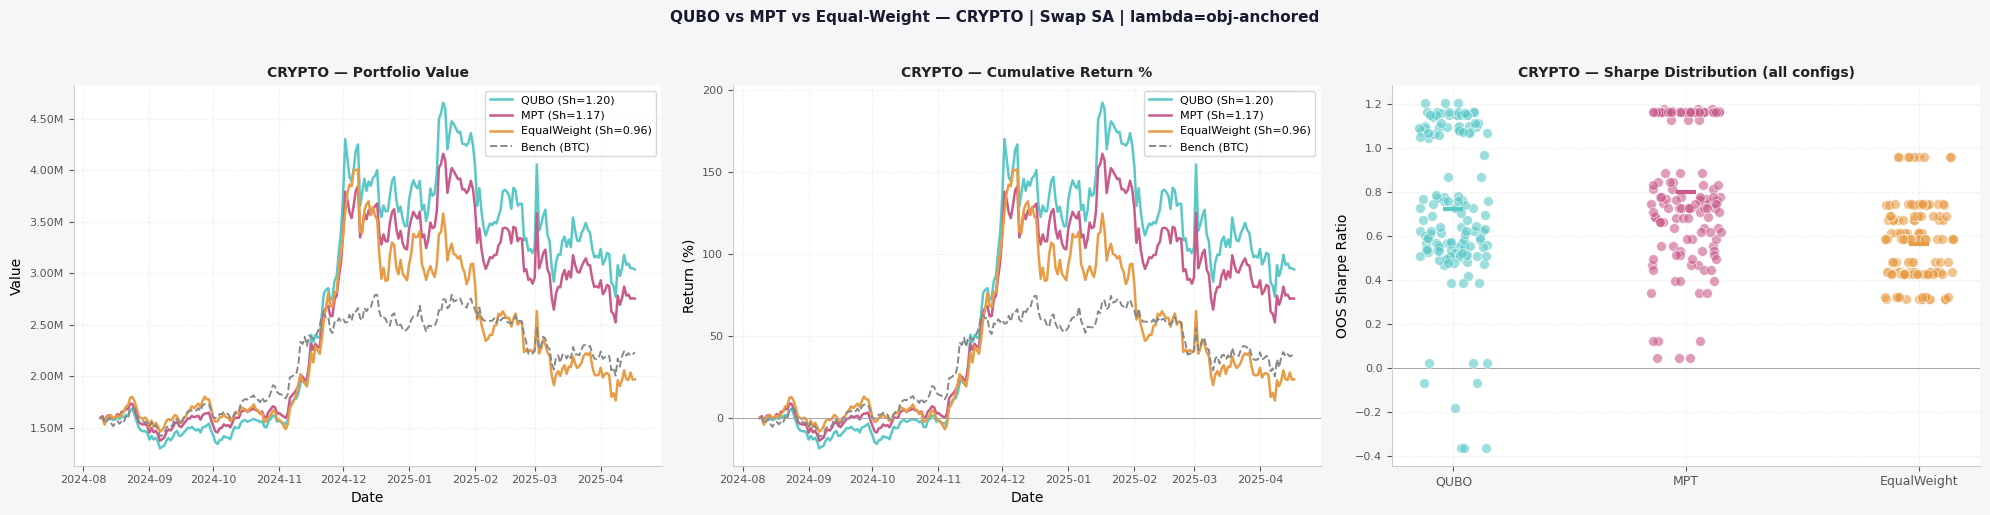

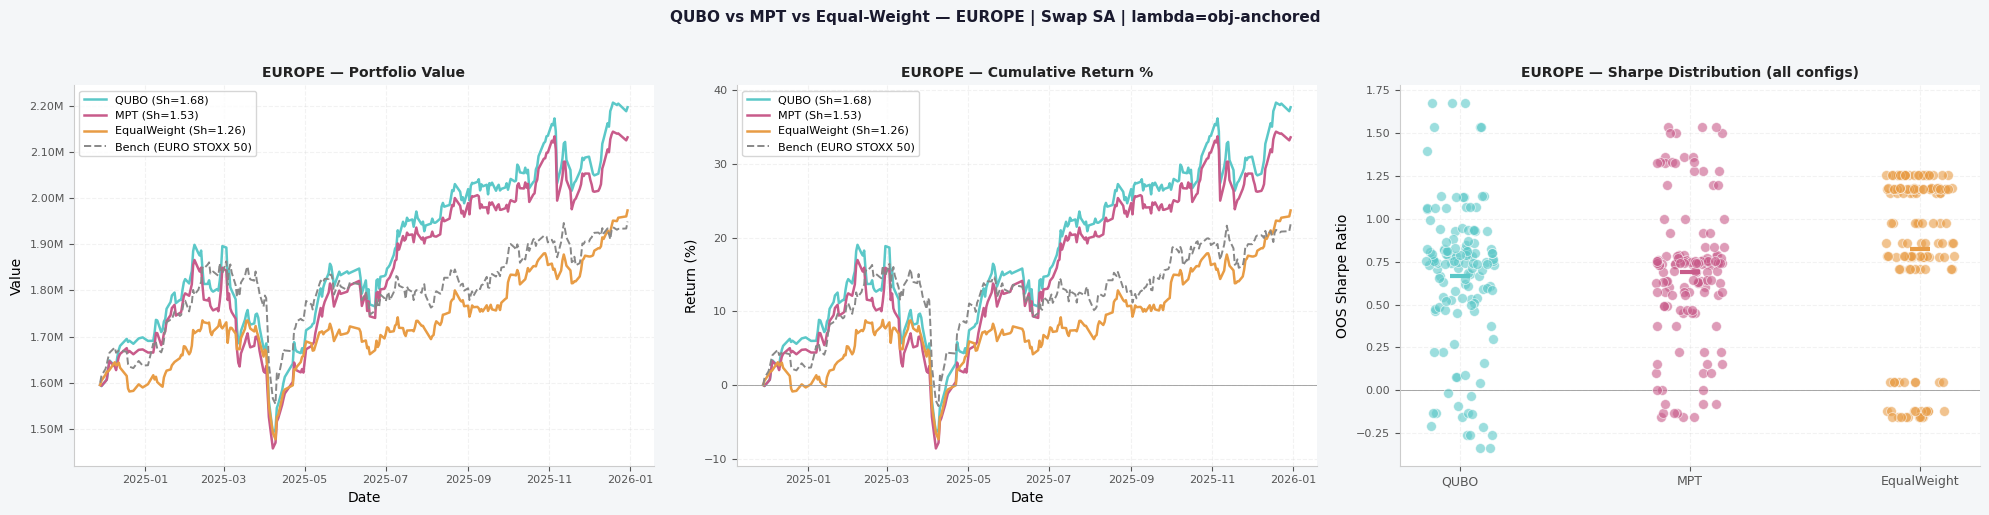

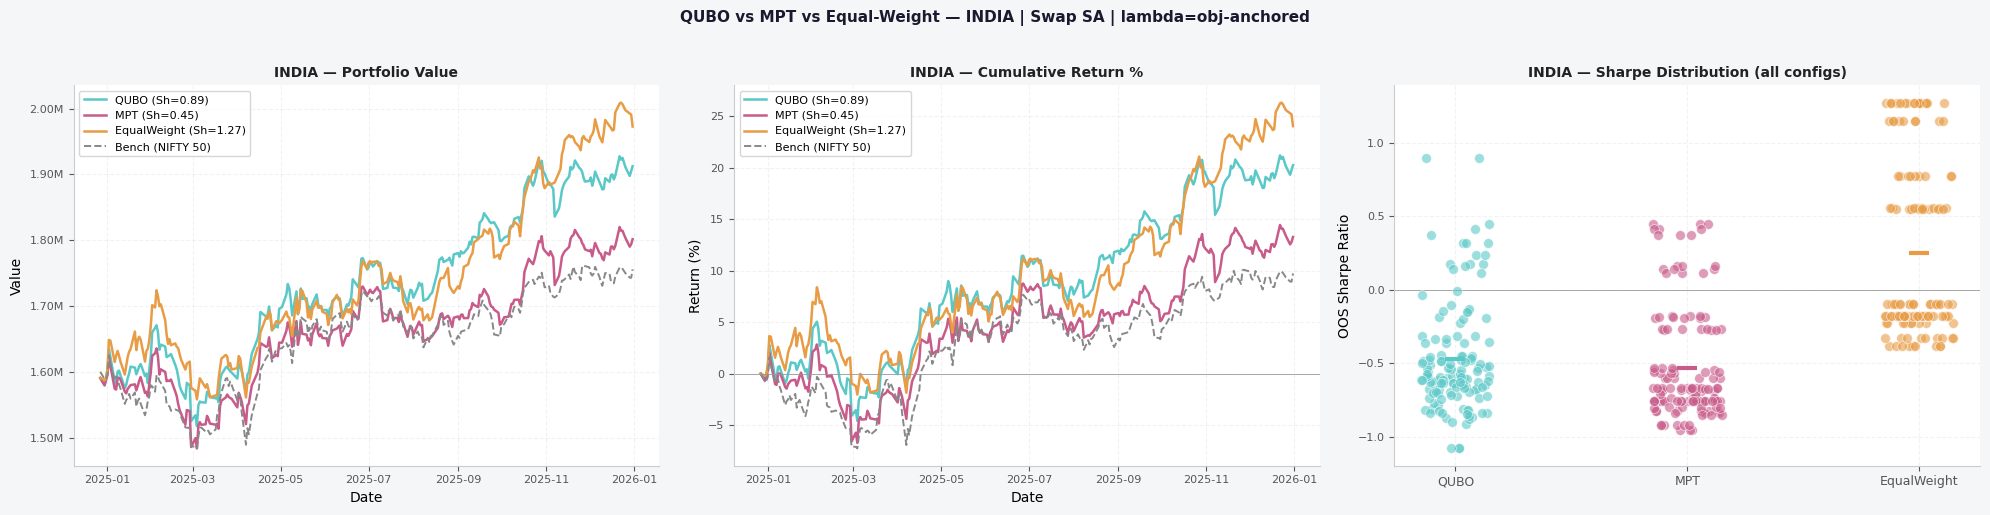

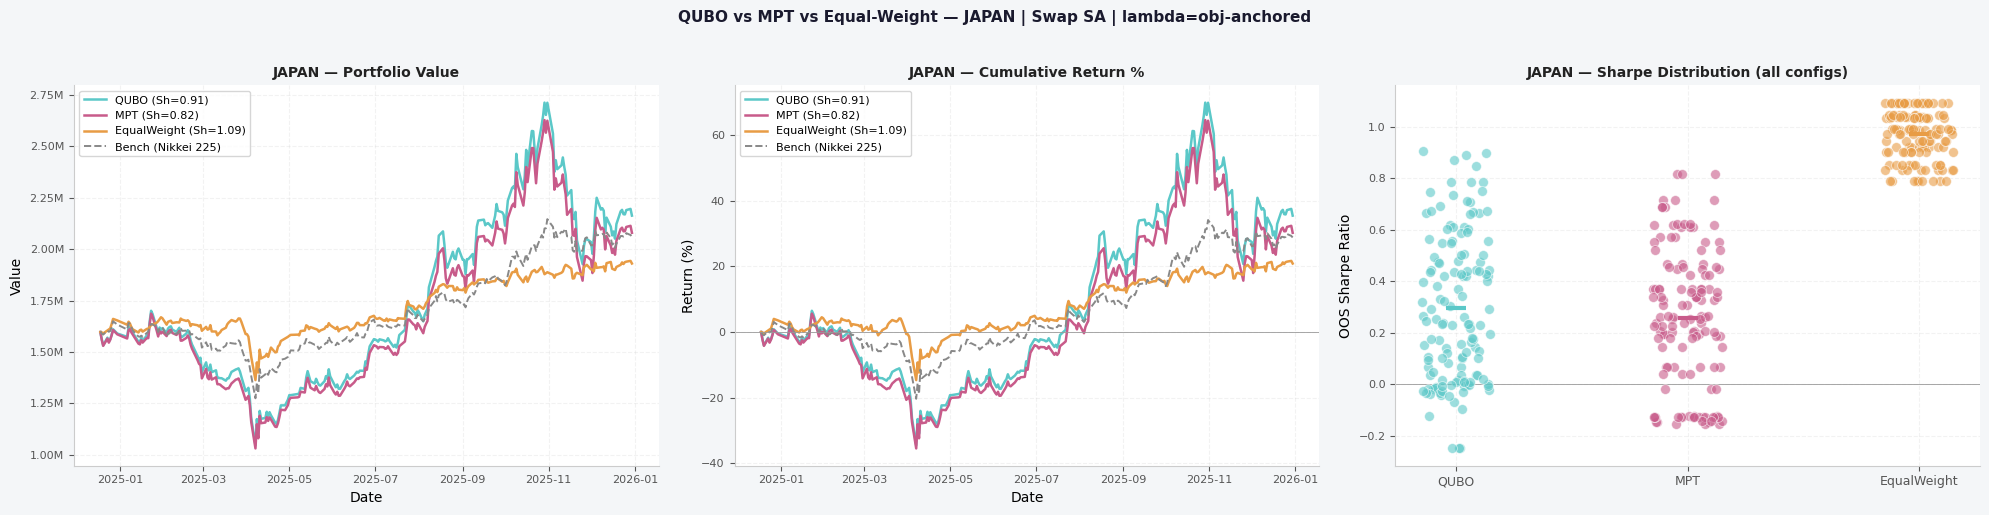

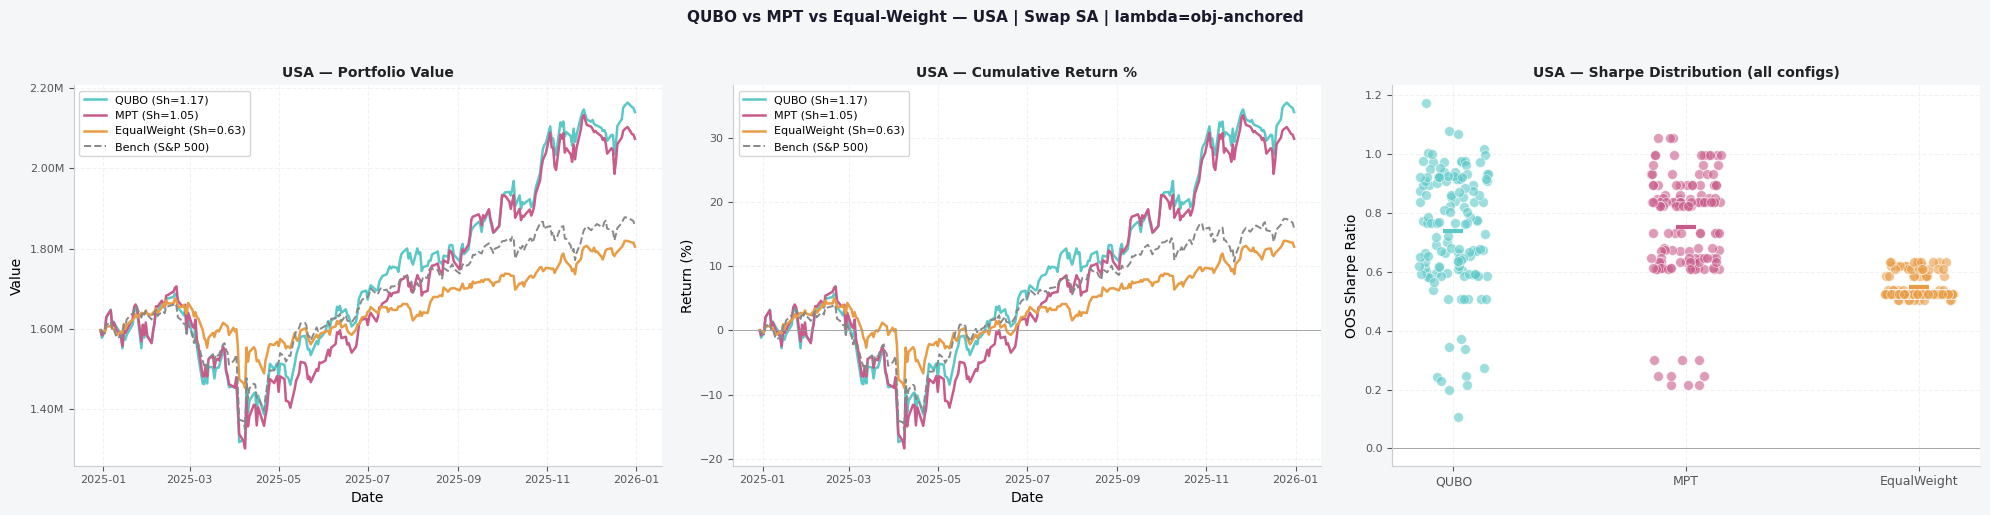

21:32:22 - INFO - [OK] Strategy comparison complete


[OK] Strategy comparison complete

[SAVING] EXPORTING RESULTS



21:32:28 - INFO - [OK] Results saved to results\experiment_results_20260426_213222.csv
21:32:28 - INFO - ================================================================================
21:32:28 - INFO - [DONE] Full experiment execution complete
21:32:28 - INFO - Logs written to: logs\qubo_optimization_20260426_211939.log
21:32:28 - INFO - Results saved to: results\experiment_results_20260426_213222.csv
21:32:28 - INFO - ================================================================================


[OK] Results saved to results\experiment_results_20260426_213222.csv

[DONE] EXPERIMENT EXECUTION COMPLETE



In [35]:
print(f"\n{'='*80}")
print("[INIT] DOWNLOADING MARKET DATA")
print(f"{'='*80}\n")

price_data  = {}
volume_data = {}
bench_data  = {}

for m in MARKETS:
    try:
        print(f"\n[{m.upper()}] Starting data download...")
        price_data[m], volume_data[m] = download_data(m, START_DATE, END_DATE)
        bench_data[m]                 = download_benchmark_data(m, START_DATE, END_DATE)
        logger.info(f"[OK] {m.upper()} data ready\n")
        print(f"[OK] {m.upper()} complete\n")
    except Exception as e:
        logger.error(f"[FAIL] Data download failed for {m}: {e}", exc_info=True)
        print(f"[ERROR] Failed to download {m}: {e}\n")

print(f"\n{'='*80}")
print("[MAIN] RUNNING EXPERIMENT GRID")
print(f"{'='*80}\n")

df_all = run_experiment_grid(
    markets        = MARKETS,
    universe_sizes = UNIVERSE_SIZES,
    cardinalities  = CARDINALITIES,
    q_values       = Q_VALUES,
    lookbacks      = LOOKBACKS,
    backtest_days  = BACKTEST_DAYS,
    div_penalty    = DIV_PENALTY,
    price_data     = price_data,
    volume_data    = volume_data,
    bench_prices   = bench_data,
)

logger.info(f"\n{'='*80}")
logger.info(f"[COMPLETE] Grid execution complete: {len(df_all)} total results")
logger.info(f"{'='*80}")

print(f"\n{'='*80}")
print("[REPORTING] FINAL RESULTS")
print(f"{'='*80}\n")
print_final_report(df_all)

print(f"\n{'='*80}")
print("[PLOTS] GENERATING VISUALIZATIONS")
print(f"{'='*80}\n")

try:
    generate_all_plots(
        df_all,
        plots_dir       = "plots/qubo_swap_sa",
        price_data      = price_data,
        volume_data     = volume_data,
        bench_prices    = bench_data,
        backtest_days   = BACKTEST_DAYS,
        initial_capital = 1_600_000,
    )
    logger.info("[OK] Plots generated")
    print("[OK] Plots complete")
except Exception as e:
    logger.error(f"[FAIL] Plot generation failed: {e}", exc_info=True)
    print(f"[ERROR] Plot generation failed: {e}\n")

print(f"\n{'='*80}")
print("[COMPARISON] STRATEGY COMPARISON")
print(f"{'='*80}\n")

try:
    plot_strategy_comparison(
        df_all, bench_data,
        price_data      = price_data,
        volume_data     = volume_data,
        initial_capital = 1_600_000,
        plots_dir       = "plots/qubo_swap_sa",
    )
    logger.info("[OK] Strategy comparison complete")
    print("[OK] Strategy comparison complete")
except Exception as e:
    logger.error(f"[FAIL] Strategy comparison failed: {e}", exc_info=True)
    import traceback; traceback.print_exc()
    print(f"[ERROR] Strategy comparison failed\n")

print(f"\n{'='*80}")
print("[SAVING] EXPORTING RESULTS")
print(f"{'='*80}\n")

# Save results to CSV
results_dir = "results"
os.makedirs(results_dir, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
results_file = os.path.join(results_dir, f"experiment_results_{timestamp}.csv")

try:
    df_all.to_csv(results_file, index=False)
    logger.info(f"[OK] Results saved to {results_file}")
    print(f"[OK] Results saved to {results_file}")
except Exception as e:
    logger.error(f"[FAIL] Failed to save results: {e}", exc_info=True)
    print(f"[ERROR] Failed to save results: {e}\n")

print(f"\n{'='*80}")
print("[DONE] EXPERIMENT EXECUTION COMPLETE")
print(f"{'='*80}\n")
logger.info(f"{'='*80}")
logger.info("[DONE] Full experiment execution complete")
logger.info(f"Logs written to: {log_file}")
logger.info(f"Results saved to: {results_file}")
logger.info(f"{'='*80}")